# Phase 1: Background margin study

## Section 1 - Purpose and overview

This study chooses the background margin for the two classifiers kept so far: V0, one prototype per class, and V2, every labelled reference patch as a prototype (multi-prototype study). It also asks whether V2, with its own margin, keeps its advantages and recovers what it lost in the continuous perception of assembly_2.

What the margin does. Each patch has a similarity with every class. Let d be the similarity of the best class other than background minus the similarity of background. The patch takes that class if d is at least the margin m, and background otherwise. The margin decides only between background and the other classes, the pieces and the hand. It never decides between two pieces.

The margin is a bias on the background class. Mensink et al. (2013, Sect. 3.4, Eq. 21) write the nearest class mean classifier as a dot product plus a bias for each class, and these biases set the prior probabilities of the classes. With m = 0 each patch takes its most similar class. With equal costs for all errors, choosing the most probable class minimizes the number of errors (Bishop 2006, Sect. 1.5.1). When one error costs more than another, the decision boundary moves to avoid the costlier one (Bishop 2006, Sect. 1.5.2). The direction depends only on which error costs more. A positive margin favours background, a negative margin favours the other classes. Until now the margin could only be zero or positive. From this study, negative values are allowed (assign_labels, src/perception/prototypes.py).

Why the margin is studied now. The margin was introduced in the first video demo of the perception notebook, written before the pipeline was rebuilt, to remove false pieces predicted on empty background, such as the wall. The classifier must always choose a class, and a background patch can be slightly more similar to a piece than to background. The value 0.03 was set by watching the demo video, with one prototype per class: at this value the false pieces on empty background had disappeared, while no real piece had disappeared. This visual criterion looks at isolated false pieces. It does not see the bleeding of the pieces into the table at their borders, which on screen looks like slightly larger pieces rather than errors. Section 5.4 measures what the value removes on the reference frames.

The value was therefore a reasonable starting point, but it was never measured, it has no stated range, and it was set for one classifier only. The rebuilt pipeline kept it and marked it as provisional (pipeline, Sections 2.5 and 9). Since then it has been used unchanged by every study, also in their decision rules: the support set and the choice of V2 were both decided at margin 0.03 (support-set study; multi-prototype study, Section 8). This study starts from it because every previous result depends on it, and replaces it with a value chosen by a stated procedure, separately for each classifier.

On the validation frames, the margin 0.03 raises the mIoU of V0 with the arms merged from 0.670 to 0.725, while V2 barely changes, from 0.864 to 0.861 (multi-prototype study, Observation 5.2). In the continuous perception of assembly_2, V2 rarely saw the loose arm_2 on the table: in 10% of the frames before its pick, against 99% with V0. At rest, the presence of arm_2 changed about 5 times per second with V2, against 0.2 with V0 (multi-prototype study, Addendum; continuous_analysis.py on the saved labels).

Hypothesis, not verified: with 37,864 background prototypes, background often wins by a small difference, and a lower or negative margin would recover these patches. A margin of zero or above cannot recover a patch where background already has the highest similarity.

Where the margin is chosen. Choosing the margin on the validation frames would make their results optimistic (Cawley and Talbot 2010, Sect. 4.4 and 5; Bishop 2006, Sect. 1.3). It is chosen instead on the 10 reference frames, by cross-validation (Bishop 2006, Sect. 1.3). One reference sequence at a time is left out. The prototypes are built from the other frames, and the frames left out are classified and compared with their annotations.

Whole sequences are left out, not single frames. Frames of one recording look alike, and for V2 a nearly identical frame among the prototypes would make the task too easy. The same reason splits validation and test by recording (Sener et al. 2022, Sect. 4.6).

The selection needs no annotation beyond the reference frames, which the method needs anyway. In a new assembly it can be repeated automatically. Cawley and Talbot (2010, Sect. 6) recommend treating model selection as part of fitting, also in operational use.

Details of the selection. The hand prototypes come from one frame only, caos_f0211. In the fold that leaves out the caos sequence there is no hand class, so the hand patches of that fold are ignored. The mIoU changes only when the margin crosses the d of some patch. It is therefore computed at every value where at least one label changes, with no grid to choose, and zero and negative values are included. The chosen margin m* is the middle of the best interval, the value farthest from both of its ends. If two separate intervals tie, the one closest to zero is taken, since zero adds no preference. The margin is chosen separately for V0 and V2, because a class mean and a maximum over many prototypes give similarities on different scales (Section 4).

Hypotheses, written before running. For V0, m* is positive, since 0.03 already improves V0 on validation. For V2, m* is lower than for V0, possibly negative.

Decision rule, fixed before running. For each variant, the mIoU at m* is compared with the mIoU at margin 0 on the validation frames, with the arms merged on the main metric, by the paired 95% bootstrap interval of the difference (Koehn 2004, Sect. 6), on the same resamples as the previous studies. If the interval lies entirely below zero, the margin is 0, otherwise m*. Zero is the reference because it is the decision without any preference between background and pieces. The value 0.03 is reported only. Then V2 is compared with V0, each at its chosen margin. If the interval lies entirely above zero, the choice of V2 is confirmed. Otherwise the study stops and the result is discussed before any change to the pipeline.

Reported, outside the rule. The mIoU over the 10 pieces and with the boundary ring ignored, the per-class IoU, and three kinds of error separately: background predicted as a piece, near the pieces or far from them; a piece predicted as background; a piece predicted as another piece. Also the targeted measures of the multi-prototype study: the empty mouth slot, the identity of the arms, the loose mouth. If the chosen margin visibly increases the false positives far from the pieces, this is discussed before updating the pipeline.

After the decision, as an exploratory check outside the rule, continuous perception is run again on assembly_2 for V0 and V2 at 0.03 and at the chosen margins, and analysed with continuous_analysis.py unchanged. Its thresholds are provisional. A diagnostic also asks why arm_2 is missed: whether background wins outright, or the margin rejects it. The test sequence (assembly_1) is not read.

Section 2 sets the configuration. Section 3 checks that the new assign_labels reproduces the previous results. Section 4 describes d for both variants. Section 5 chooses the margin on the reference frames. Section 6 applies the decision rule on the validation frames. Section 7 reports the errors and the targeted measures. Section 8 is the continuous perception. Section 9 gives the conclusions.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 1:

Mensink et al. 2013, Sect. 3.4, Eq. (21): the nearest class mean classifier written with the dot product and a class-specific bias; the biases define the prior probabilities of the classes.

Bishop 2006, Pattern Recognition and Machine Learning, Sect. 1.5.1: the number of errors is smallest when each input is assigned to the class with the largest posterior probability. Sect. 1.5.2, Eq. (1.80) and (1.81): with a loss matrix, each input is assigned to the class that minimizes the expected loss, so errors of different cost move the decision boundary. Sect. 1.3: when a design is iterated many times on a small validation set, it can over-fit that set; cross-validation (Figure 1.18) uses part of the data to build the model and the rest to evaluate it, in turn.

Cawley and Talbot 2010, Sect. 4.4: optimizing a selection criterion on a finite sample over-fits, more so with small samples and many choices. Sect. 5: performance estimated on the data used for selection is optimistically biased; selection must be treated as part of fitting. Sect. 6: model selection should be repeated independently in each trial, which also reflects practice in operational use.

Sener et al. 2022, Assembly101, Sect. 4.6: splits made by recording.

Koehn 2004, Sect. 6: paired bootstrap resampling.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 2 - Configuration

All paths, frames and hyperparameters in one place. The values are those of the multi-prototype study (Section 2.4 and 2.5), with the same 10 reference frames and 8 validation frames. Only the margin changes: 0 is the reference of the decision rule, and 0.03 is kept only to be reported. The cross-validation folds are the reference sequences.

In [1]:
# 2.1 Dependencies: install once per environment with pip install -r requirements.txt (README, Setup)

In [2]:
# 2.2 Imports
%load_ext autoreload
%autoreload 2

import sys
import json
import hashlib
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
import matplotlib.patches as mpatches
import cv2

In [ ]:
# 2.3 Paths and shared module
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))   # makes src/perception importable from notebooks/

MODEL_DIR = PROJECT_ROOT / "models" / "c_radio_weights"
FRAMES_DIR = PROJECT_ROOT / "data" / "extracted_frames"
VIDEO_PATH = PROJECT_ROOT / "data" / "raw_videos" / "assembly_2.mp4"              # Section 8
EVENTS_PATH = PROJECT_ROOT / "configs" / "assembly_2_events.json"                 # Section 8
SCRATCH_DIR = PROJECT_ROOT / "outputs" / "scratch"                                # labels at 0.03 of the Addendum (Section 8)
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase_1_margin_study"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

for name, path in {"MODEL_DIR": MODEL_DIR, "FRAMES_DIR": FRAMES_DIR, "SRC_DIR": SRC_DIR,
                   "VIDEO_PATH": VIDEO_PATH, "EVENTS_PATH": EVENTS_PATH,
                   "labels V0 (0.03)": SCRATCH_DIR / "assembly_2_continuous_labels.npz",
                   "labels V2 (0.03)": SCRATCH_DIR / "assembly_2_continuous_labels_V2.npz"}.items():
    status = "OK" if path.exists() else "MISSING"
    print(f"[{status}] {name}: {path}")

# Shared code (src/perception)
from perception.classes import CLASS_NAMES, BACKGROUND_ID, HAND_LABEL, PIECE_LABELS, IGNORE_ID, PATCH_LABEL_NAMES, CLASS_COLORS
from perception.features import FeatureExtractor
from perception.labels import sequence_of, check_annotation, rasterize_annotation, patch_label_grid
from perception.prototypes import (build_prototypes, stack_prototypes, patch_prototypes, class_similarities,
                                   class_similarities_gpu, sort_by_class, assign_labels, l2_normalize)
from perception.metrics import (confusion_matrix, iou_from_confusions, mean_iou, ignore_boundary_ring,
                                MERGED_NAMES, MERGED_PIECES, merge_arms, merged_ids,
                                frame_iou, frame_miou, bootstrap_miou, bootstrap_class_iou, percentile_interval)
from perception.visualization import label_grid_to_rgb, render_overlay 

[OK] MODEL_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\models\c_radio_weights
[OK] FRAMES_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\extracted_frames
[OK] SRC_DIR: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\src
[OK] VIDEO_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\data\raw_videos\assembly_2.mp4
[OK] EVENTS_PATH: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\configs\assembly_2_events.json
[OK] labels V0 (0.03): c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\scratch\assembly_2_continuous_labels.npz
[OK] labels V2 (0.03): c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\scratch\assembly_2_continuous_labels_V2.npz


In [4]:
# 2.4 Hyperparameters
# Same values as the multi-prototype study (Section 2.4); only the background margin is new.

# --- Feature extraction ---
DEVICE = "cuda"
DTYPE = torch.bfloat16          # input resolution: native 1024x1024 (resolution study)

# --- Border-artifact check (Section 4.5) ---
EXTREME_NORM_FACTOR = 5         # diagnostic only, as in the pipeline (Section 2.5, Appendix A.2): norm above 5x the median

# --- Patch labelling ---
MIN_LABEL_COVERAGE = 0.5        # same rule as the pipeline (Section 5)

# --- Background margin ---
NO_MARGIN = 0.0                 # no preference between background and the other classes: reference of the rule (Section 1)
CURRENT_MARGIN = 0.03           # set by eye for V0 (pipeline, Section 9): reported only, not a candidate
PROTOTYPE_CHUNK = 4096          # prototypes compared at once by class_similarities on the CPU: memory only, results unchanged

# --- Evaluation ---
N_BOOTSTRAP = 1000              # resamples of the frames (support-set study, Section 5.4)
BOUNDARY_RING = 1               # secondary metric: background patches within 1 patch of an object are ignored

# --- Reproducibility ---
RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)
_ = torch.manual_seed(RANDOM_SEED)

In [5]:
# 2.5 Frames and split
# Validation: the chosen margins are checked here (decision rule, Section 1).
# Test: held out until the end of all studies. This notebook never reads a test frame.
VALIDATION_SEQUENCES = {"assembly_2", "1_disassembled_controlled_caos"}
TEST_SEQUENCES = {"assembly_1"}
assert not VALIDATION_SEQUENCES & TEST_SEQUENCES


def frame_path(frame, suffix=".jpg"):
    """Path of a frame or of its annotation. Refuses test frames, so the test set cannot be read by mistake."""
    assert sequence_of(frame) not in TEST_SEQUENCES, f"{frame} belongs to the held-out test set"
    return FRAMES_DIR / f"{frame}{suffix}"


# Support set of 10 frames, in the order of the multi-prototype study (Section 2.5)
REFERENCE_FRAMES = [
    {"frame": "5_assembled_f0002",            "role": "assembled",                   "use_labels": PIECE_LABELS},
    {"frame": "caos_f0149",                   "role": "partially assembled",         "use_labels": PIECE_LABELS},
    {"frame": "5_assembled_f0019",            "role": "assembled, 3/4 view",         "use_labels": PIECE_LABELS},
    {"frame": "3_disassembled_ordered_f0001", "role": "disassembled",                "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "2_disassembled_caos_f0016",    "role": "disassembled, top-down view", "use_labels": PIECE_LABELS - {"base"}},
    {"frame": "Take_3_1_Base_f0099",          "role": "base only, upright",          "use_labels": {"base"}},
    {"frame": "Take_3_1_Base_f0131",          "role": "base only, lying",            "use_labels": {"base"}},
    {"frame": "caos_f0211",                   "role": "hands",                       "use_labels": {HAND_LABEL}},
    {"frame": "4_partially_assembled_f0002",  "role": "body on base, face incomplete (empty mouth slot); mouth loose at 3/4",
     "use_labels": {"body", "mouth"}},
    {"frame": "caos_f0043",                   "role": "mouth loose, side view",      "use_labels": {"mouth"}},
]

# Validation frames in the order of the previous studies: bootstrap resamples pick frames by position
VALIDATION_FRAMES = [
    {"frame": "assembly_2_f0003", "stage": "all pieces loose"},
    {"frame": "assembly_2_f0017", "stage": "body on base"},
    {"frame": "assembly_2_f0030", "stage": "hands: piece held in hand"},
    {"frame": "assembly_2_f0046", "stage": "face (eyes, nose, moustache, mouth)"},
    {"frame": "assembly_2_f0057", "stage": "ears mounted"},
    {"frame": "assembly_2_f0068", "stage": "arms mounted"},
    {"frame": "1_disassembled_controlled_caos_f0001", "stage": "disassembled, front view", "exclude": {"base"}},
    {"frame": "1_disassembled_controlled_caos_f0016", "stage": "disassembled, side view",  "exclude": {"base"}},
]

# No leakage: reference frames never come from validation or test sequences
for ref in REFERENCE_FRAMES:
    assert sequence_of(ref["frame"]) not in VALIDATION_SEQUENCES | TEST_SEQUENCES, f"Leakage: {ref['frame']}"
    ref["image_path"], ref["json_path"] = frame_path(ref["frame"]), frame_path(ref["frame"], ".json")
for val in VALIDATION_FRAMES:
    assert sequence_of(val["frame"]) in VALIDATION_SEQUENCES, f"{val['frame']} is not a validation frame"
    assert frame_path(val["frame"]).exists(), f"Missing frame: {val['frame']}"

GT_LABELS = PIECE_LABELS | {HAND_LABEL}   # validation ground truth: every official class; legacy labels become ignored
EXCLUDED = [{CLASS_NAMES.index(name) for name in val.get("exclude", set())} for val in VALIDATION_FRAMES]

# Cross-validation folds (Section 1): one reference sequence per fold, frames in support-set order
FOLDS = {}
for ref in REFERENCE_FRAMES:
    FOLDS.setdefault(sequence_of(ref["frame"]), []).append(ref["frame"])
assert len(FOLDS) == 6, f"Expected 6 reference sequences, found {len(FOLDS)}"

print(f"{len(REFERENCE_FRAMES)} reference frames in {len(FOLDS)} folds, {len(VALIDATION_FRAMES)} validation frames")
display(pd.DataFrame({"frames left out": [", ".join(frames) for frames in FOLDS.values()],
                      "n": [len(frames) for frames in FOLDS.values()]}, index=list(FOLDS)))

10 reference frames in 6 folds, 8 validation frames


,frames left out,n
5_assembled,"5_assembled_f0002, 5_assembled_f0019",2
caos,"caos_f0149, caos_f0211, caos_f0043",3
3_disassembled_ordered,3_disassembled_ordered_f0001,1
2_disassembled_caos,2_disassembled_caos_f0016,1
Take_3_1_Base,"Take_3_1_Base_f0099, Take_3_1_Base_f0131",2
4_partially_assembled,4_partially_assembled_f0002,1


Observation 2.5: The 10 reference frames form 6 folds, one per sequence. The largest fold is caos, with 3 frames, and it is the only one that contains hand (caos_f0211). In that fold there is no hand prototype, so the hand patches are ignored (Section 1). Three folds have a single frame: 3_disassembled_ordered, 2_disassembled_caos and 4_partially_assembled.

In [6]:
# 2.6 Annotation fingerprints: data/ is not tracked by git, so the notebook records which annotations it used
def fingerprint(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:12]

display(pd.DataFrame({
    "set": [f"reference ({sequence_of(ref['frame'])})" for ref in REFERENCE_FRAMES] + ["validation"] * len(VALIDATION_FRAMES),
    "annotation sha256": [fingerprint(ref["json_path"]) for ref in REFERENCE_FRAMES]
                         + [fingerprint(frame_path(val["frame"], ".json")) for val in VALIDATION_FRAMES],
}, index=[ref["frame"] for ref in REFERENCE_FRAMES] + [val["frame"] for val in VALIDATION_FRAMES]))

,set,annotation sha256
5_assembled_f0002,reference (5_assembled),e85d1c179582
caos_f0149,reference (caos),14f88d7cf080
5_assembled_f0019,reference (5_assembled),1cd8cdcc2c9b
3_disassembled_ordered_f0001,reference (3_disassembled_ordered),319c3601f0a1
2_disassembled_caos_f0016,reference (2_disassembled_caos),f17ab6af8218
Take_3_1_Base_f0099,reference (Take_3_1_Base),853e60024c17
Take_3_1_Base_f0131,reference (Take_3_1_Base),f07f67aae3a9
caos_f0211,reference (caos),3c56b4804e54
4_partially_assembled_f0002,reference (4_partially_assembled),32a94339f2b4
caos_f0043,reference (caos),3b555dd93c2c


Observation 2.6: All 18 annotation fingerprints, 10 reference and 8 validation frames, are identical to those recorded by the multi-prototype study (Section 2.6). This study uses exactly the same annotations.

In [7]:
# 2.7 Environment
print(f"Python       : {platform.python_version()}")
print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU          : {torch.cuda.get_device_name(0)}")

Python       : 3.10.0
PyTorch      : 2.5.1+cu121
Transformers : 5.17.0
CUDA         : True
GPU          : NVIDIA GeForce RTX 4060 Laptop GPU


------------------------------------------------------------------------------------------------------------------------------------------

References Section 2: none. The values and frames are those of the multi-prototype study (Section 2.4 and 2.5); the folds follow the cross-validation by sequence of Section 1.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 3 - Regression check

From this study, assign_labels also accepts negative margins (Section 1). For margins of zero or above its code is the one of v1.5, so the labels should not change. This section checks it, so that later differences come from the margin and not from the code.

Three things are checked. First, at margin 0 and 0.03 the new assign_labels gives exactly the labels of the v1.5 function, copied here, for V0 and V2 on every validation patch. Second, the mIoU of V0 and V2 at these margins equals the one reported by the multi-prototype study (Observation 5.2). Third, at negative margins the labels follow the definition of Section 1: a patch takes the best class other than background if d is at least the margin, and background otherwise. The negative margins of this check are taken from the data, as quantiles of the negative values of d. They only exercise the code and are not candidates.

The features of the 10 reference frames and of the 8 validation frames are extracted here once, and the ground truth is prepared as in the multi-prototype study (Section 3.3). Class similarities are computed on the CPU with class_similarities, the code used by the multi-prototype study for its measures, so the comparison is with the same computation.

In [8]:
# 3.1 Loading the model (shared FeatureExtractor, same settings as the pipeline)
extractor = FeatureExtractor(MODEL_DIR, device=DEVICE, dtype=DTYPE)
PATCH_SIZE = extractor.patch_size
print(f"Model loaded, patch size {PATCH_SIZE}x{PATCH_SIZE}")

Loading weights:   0%|          | 0/330 [00:00<?, ?it/s]

Model loaded, patch size 16x16


In [9]:
# 3.2 Reference frames: features and patch labels (use_labels); the two variants on all 10 frames
for ref in REFERENCE_FRAMES:
    check_annotation(ref["image_path"], ref["json_path"])
    image = Image.open(ref["image_path"]).convert("RGB")
    ref["features"], size = extractor.extract(image)
    ref["patch_labels"], _ = patch_label_grid(rasterize_annotation(ref["json_path"], ref["use_labels"], size),
                                              PATCH_SIZE, MIN_LABEL_COVERAGE)

prototypes_v0, _ = build_prototypes(REFERENCE_FRAMES)
VARIANTS = {
    "V0": (stack_prototypes(prototypes_v0), np.arange(len(CLASS_NAMES))),   # one prototype per class, in class order
    "V2": patch_prototypes(REFERENCE_FRAMES),                              # every labelled reference patch
}
display(pd.DataFrame({name: {"prototypes": len(owners), "background prototypes": int((owners == BACKGROUND_ID).sum())}
                      for name, (prototypes, owners) in VARIANTS.items()}).T)

,prototypes,background prototypes
V0,12,1
V2,39125,37864


Observation 3.2: V0 has 12 prototypes, one per class, of which one is background. V2 has 39,125 prototypes, of which 37,864 are background. Both numbers are those of the multi-prototype study (Observation 4.2).

In [10]:
# 3.3 Validation frames: ground truth (multi-prototype study, Section 3.3), features, and class similarities
# of both variants on the CPU (class_similarities, as in the multi-prototype study, Section 5.1)
for val in VALIDATION_FRAMES:
    image_path, json_path = frame_path(val["frame"]), frame_path(val["frame"], ".json")
    check_annotation(image_path, json_path)
    image = Image.open(image_path).convert("RGB")
    val["features"], size = extractor.extract(image)
    val["gt_labels"], _ = patch_label_grid(rasterize_annotation(json_path, GT_LABELS, size), PATCH_SIZE, MIN_LABEL_COVERAGE)
    val["gt_tolerant"] = ignore_boundary_ring(val["gt_labels"], BOUNDARY_RING)

SIMILARITIES = {name: [class_similarities(val["features"], prototypes, owners, chunk=PROTOTYPE_CHUNK)
                       for val in VALIDATION_FRAMES]
                for name, (prototypes, owners) in VARIANTS.items()}
print("Similarities computed:", {name: len(s) for name, s in SIMILARITIES.items()}, "validation frames per variant")

Similarities computed: {'V0': 8, 'V2': 8} validation frames per variant


In [11]:
# 3.4 Regression check of assign_labels
def assign_labels_v15(similarities, margin, background_id=BACKGROUND_ID):
    """assign_labels as in v1.5 (copied unchanged): the reference for margins of zero or above."""
    labels = similarities.argmax(axis=-1)
    best = similarities.max(axis=-1)
    rejected = (labels != background_id) & (best - similarities[..., background_id] < margin)
    return np.where(rejected, background_id, labels)


def background_gap(similarities):
    """d = similarity of the best class other than background - similarity of background (Section 1),
    and the index of that class. Arrays of shape (h, w)."""
    others = similarities.copy()
    others[..., BACKGROUND_ID] = -np.inf
    return others.max(axis=-1) - similarities[..., BACKGROUND_ID], others.argmax(axis=-1)


def variant_confusions(name, margin, gt_key="gt_labels"):
    """Per-frame confusion matrices of one variant at one background margin."""
    return [confusion_matrix(val[gt_key], assign_labels(similarities, margin))
            for val, similarities in zip(VALIDATION_FRAMES, SIMILARITIES[name])]


# (a) Same labels as v1.5 at margin 0 and 0.03, on every validation patch
rows = {}
for name in VARIANTS:
    rows[name] = {f"patches with a different label, margin {margin}":
                  sum(int((assign_labels(s, margin) != assign_labels_v15(s, margin)).sum()) for s in SIMILARITIES[name])
                  for margin in [NO_MARGIN, CURRENT_MARGIN]}
display(pd.DataFrame(rows).T)
print(f"Patches compared per margin and variant: {sum(s[..., 0].size for s in SIMILARITIES['V0'])}")

# (b) Same mIoU as the multi-prototype study (Observation 5.2, values rounded to 3 decimals there)
REPORTED = {  # (variant, ground truth, margin): (10 pieces, arms merged)
    ("V0", "gt_labels", 0.0): (0.626, 0.670), ("V0", "gt_labels", 0.03): (0.673, 0.725),
    ("V0", "gt_tolerant", 0.0): (0.742, 0.811), ("V0", "gt_tolerant", 0.03): (0.753, 0.823),
    ("V2", "gt_labels", 0.0): (0.823, 0.864), ("V2", "gt_labels", 0.03): (0.818, 0.861),
    ("V2", "gt_tolerant", 0.0): (0.823, 0.865), ("V2", "gt_tolerant", 0.03): (0.818, 0.861),
}
rows = []
for (name, gt_key, margin), (reported_10, reported_merged) in REPORTED.items():
    confusions = variant_confusions(name, margin, gt_key)
    obtained_10 = round(frame_miou(confusions, EXCLUDED), 3)
    obtained_merged = round(frame_miou(confusions, EXCLUDED, merge=True), 3)
    rows.append({"variant": name, "metric": gt_key, "margin": margin,
                 "10 pieces": obtained_10, "reported": reported_10,
                 "arms merged": obtained_merged, "reported ": reported_merged,
                 "equal": obtained_10 == reported_10 and obtained_merged == reported_merged})
display(pd.DataFrame(rows))

# (c) Negative margins follow the definition of Section 1; exact ties at d = 0 are counted
rows = {}
for name in VARIANTS:
    gaps = [background_gap(s) for s in SIMILARITIES[name]]
    d_all = np.concatenate([d.ravel() for d, _ in gaps])
    test_margins = np.quantile(d_all[d_all < 0], [0.1, 0.5, 0.9])     # taken from the data: code check only
    mismatches = 0
    for s, (d, best_other) in zip(SIMILARITIES[name], gaps):
        for margin in test_margins:
            expected = np.where(d >= margin, best_other, BACKGROUND_ID)
            mismatches += int((assign_labels(s, margin) != expected).sum())
    rows[name] = {"test margins": np.round(test_margins, 4).tolist(),
                  "patches different from the definition": mismatches,
                  "exact ties d = 0": int((d_all == 0).sum())}
display(pd.DataFrame(rows).T)

,"patches with a different label, margin 0.0","patches with a different label, margin 0.03"
V0,0,0
V2,0,0


Patches compared per margin and variant: 32768


,variant,metric,margin,10 pieces,reported,arms merged,reported,equal
0,V0,gt_labels,0.00,0.626,0.626,0.670,0.670,True
1,V0,gt_labels,0.03,0.673,0.673,0.725,0.725,True
2,V0,gt_tolerant,0.00,0.742,0.742,0.811,0.811,True
3,V0,gt_tolerant,0.03,0.753,0.753,0.823,0.823,True
4,V2,gt_labels,0.00,0.823,0.823,0.864,0.864,True
5,V2,gt_labels,0.03,0.818,0.818,0.861,0.861,True
6,V2,gt_tolerant,0.00,0.823,0.823,0.865,0.865,True
7,V2,gt_tolerant,0.03,0.818,0.818,0.861,0.861,True


,test margins,patches different from the definition,exact ties d = 0
V0,"[-0.2518, -0.2125, -0.1488]",0,0
V2,"[-0.375, -0.2883, -0.1928]",0,0


Observation 3.4: The new assign_labels gives exactly the labels of the v1.5 function at margin 0 and 0.03: no patch differs out of 32,768 validation patches, for V0 and V2. The mIoU of both variants equals the values reported by the multi-prototype study in all eight settings (Observation 5.2). At negative margins the labels follow the definition of Section 1 on every patch, at three test margins taken from the data: −0.252, −0.213 and −0.149 for V0, and −0.375, −0.288 and −0.193 for V2. No patch has an exact tie between background and another class (d = 0), so the convention for ties does not affect any result. The extension of assign_labels can therefore be used in the rest of the study.

The test margins are quantiles of the negative values of d, that is, of the patches where background wins. Half of these patches have d below −0.213 with V0 and below −0.288 with V2: background usually wins by a wide difference. How many patches lie close to zero, where the margin acts, is the subject of Section 4.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 3: none. The reference values are those of the multi-prototype study (Observation 4.2 and 5.2).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 4 - Cross-validated similarities and the gap d

This section prepares the data of the selection and describes them. Each reference frame is classified by prototypes built without its sequence, for V0 and V2 (Section 1). The class similarities obtained in this way are the input of Section 5.

In the fold that leaves out caos there is no hand prototype. The hand class then gets a similarity of minus infinity and can never be predicted, and the shared class_similarities is used unchanged on the classes present. Every other class must have a prototype in every fold, and this is checked. The ground truth of each reference frame is its own patch labels, with the same rule used for the prototypes (Section 3.2). Hand patches are ignored. Only caos_f0211 has hand patches, and it is classified in the fold without a hand prototype.

The section then describes d, the similarity of the best class other than background minus the similarity of background, separately for patches whose ground truth is background and patches whose ground truth is a piece. The margin acts only on patches with d close to it. The overlap of the two distributions shows how well background and pieces are separated by the features and the prototypes, and the margin can only choose where to cut inside it. Two values are marked: 0, the reference of the decision rule, and 0.03, the current value.

In [12]:
# 4.1 Cross-validated class similarities: each reference frame is classified by prototypes built without its sequence
HAND_ID = CLASS_NAMES.index(HAND_LABEL)


def similarities_allow_missing(features, prototypes, owners):
    """class_similarities when some classes have no prototype (hand in the caos fold). The shared function is used
    unchanged on the classes present; missing classes get -inf, so they can never be predicted."""
    present = np.unique(owners)
    compact = class_similarities(features, prototypes, np.searchsorted(present, owners),
                                 n_classes=len(present), chunk=PROTOTYPE_CHUNK)
    out = np.full(features.shape[:-1] + (len(CLASS_NAMES),), -np.inf, dtype=np.float32)
    out[..., present] = compact
    return out


def fold_variants(training):
    """V0 and V2 built from the training frames of one fold: (prototype matrix, class of each row)."""
    prototypes, _ = build_prototypes(training)
    v0_owners = np.array([i for i, name in enumerate(CLASS_NAMES) if name in prototypes])
    v0 = np.stack([prototypes[CLASS_NAMES[i]] for i in v0_owners])
    return {"V0": (v0, v0_owners), "V2": patch_prototypes(training)}


CV_SIMILARITIES = {name: [None] * len(REFERENCE_FRAMES) for name in VARIANTS}
rows = {}
for sequence, left_out in FOLDS.items():
    training = [ref for ref in REFERENCE_FRAMES if ref["frame"] not in left_out]
    variants = fold_variants(training)
    for name, (prototypes, owners) in variants.items():
        for i, ref in enumerate(REFERENCE_FRAMES):
            if ref["frame"] in left_out:
                CV_SIMILARITIES[name][i] = similarities_allow_missing(ref["features"], prototypes, owners)
    missing = [CLASS_NAMES[i] for i in range(len(CLASS_NAMES)) if i not in variants["V0"][1]]
    rows[sequence] = {"training frames": len(training),
                      "V2 prototypes": len(variants["V2"][1]),
                      "V2 background prototypes": int((variants["V2"][1] == BACKGROUND_ID).sum()),
                      "classes without prototype": ", ".join(missing) or "-"}
display(pd.DataFrame(rows).T)
assert all(row["classes without prototype"] in ("-", HAND_LABEL) for row in rows.values()), "Only hand may be missing"
assert all(s is not None for s in CV_SIMILARITIES["V0"] + CV_SIMILARITIES["V2"]), "Every frame must be classified once"

# Ground truth of the cross-validation: patch labels of each reference frame (Section 3.2), hand ignored
for ref in REFERENCE_FRAMES:
    ref["cv_gt"] = np.where(ref["patch_labels"] == HAND_ID, IGNORE_ID, ref["patch_labels"])

,training frames,V2 prototypes,V2 background prototypes,classes without prototype
5_assembled,8,31012,29948,-
caos,7,28033,27423,hand
3_disassembled_ordered,9,35233,34131,-
2_disassembled_caos,9,35172,34006,-
Take_3_1_Base,8,30967,29811,-
4_partially_assembled,9,35208,34001,-


Observation 4.1: Each fold builds the prototypes from 7 to 9 reference frames. V2 has between 28,033 and 35,233 prototypes per fold, of which 27,423 to 34,131 are background, against 39,125 and 37,864 with all 10 frames. Hand has no prototype only in the fold that leaves out caos, as expected, and every other class has a prototype in every fold. Every reference frame is classified once by each variant.

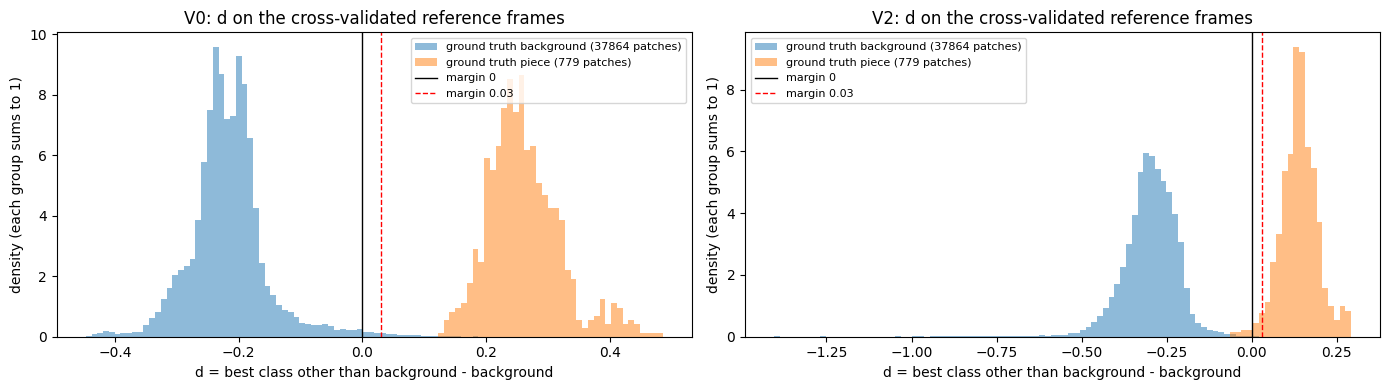

In [13]:
# 4.2 Distribution of d on the cross-validated reference frames, by ground truth (background or piece)
def gap_by_truth(name):
    """d of every cross-validated reference patch whose ground truth is background, and of every piece patch."""
    d_background, d_piece = [], []
    for ref, similarities in zip(REFERENCE_FRAMES, CV_SIMILARITIES[name]):
        d, _ = background_gap(similarities)
        d_background.append(d[ref["cv_gt"] == BACKGROUND_ID])
        d_piece.append(d[(ref["cv_gt"] != BACKGROUND_ID) & (ref["cv_gt"] != IGNORE_ID)])
    return np.concatenate(d_background), np.concatenate(d_piece)


GAPS = {name: gap_by_truth(name) for name in VARIANTS}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, VARIANTS):
    d_background, d_piece = GAPS[name]
    bins = np.linspace(min(d_background.min(), d_piece.min()), max(d_background.max(), d_piece.max()), 101)  # display only
    ax.hist(d_background, bins=bins, density=True, alpha=0.5, label=f"ground truth background ({len(d_background)} patches)")
    ax.hist(d_piece, bins=bins, density=True, alpha=0.5, label=f"ground truth piece ({len(d_piece)} patches)")
    ax.axvline(NO_MARGIN, color="black", linewidth=1, label="margin 0")
    ax.axvline(CURRENT_MARGIN, color="red", linestyle="--", linewidth=1, label="margin 0.03")
    ax.set(title=f"{name}: d on the cross-validated reference frames",
           xlabel="d = best class other than background - background", ylabel="density (each group sums to 1)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Observation 4.2: With V0 the two distributions are separated by a gap. Background patches lie mostly between about −0.4 and 0, with a long tail to the right that crosses 0, while piece patches start at about 0.12. With V2 the two distributions touch around 0: the right tail of background and the left tail of the pieces both cross it. The background of V2 also has a long tail to the left, down to about −1.4.

The scale of d differs between the variants. Compared with V0, V2 brings the pieces closer to 0, with a median of 0.139 against 0.255, and moves background further from it, with a median of −0.294 against −0.219 (Section 4.3). The same value of the margin therefore acts differently in the two variants, as expected in Section 1. The values read from the histograms are approximate; the counts are in Section 4.3.

In [14]:
# 4.3 Where margin 0 and margin 0.03 act, on the cross-validated reference frames (counts and shares)
rows = {}
for name in VARIANTS:
    d_background, d_piece = GAPS[name]
    won = np.concatenate([background_gap(s)[0].ravel() for s in CV_SIMILARITIES[name]])
    won = won[won >= 0]                                                     # patches won by a class other than background
    rows[name] = {
        "piece patches": len(d_piece),
        "piece, d < 0 (lost already at margin 0)": int((d_piece < 0).sum()),
        "piece, 0 <= d < 0.03 (lost only because of 0.03)": int(((d_piece >= 0) & (d_piece < CURRENT_MARGIN)).sum()),
        "background patches": len(d_background),
        "background, d >= 0 (false positive at margin 0)": int((d_background >= 0).sum()),
        "background, d >= 0.03 (false positive at 0.03)": int((d_background >= CURRENT_MARGIN).sum()),
        "share of non-background wins rejected by 0.03": float((won < CURRENT_MARGIN).mean()),
        "median d, piece": float(np.median(d_piece)),
        "median d, background": float(np.median(d_background)),
    }
display(pd.DataFrame(rows).round(3))

,V0,V2
piece patches,779.000,779.000
"piece, d < 0 (lost already at margin 0)",0.000,10.000
"piece, 0 <= d < 0.03 (lost only because of 0.03)",0.000,8.000
background patches,37864.000,37864.000
"background, d >= 0 (false positive at margin 0)",414.000,17.000
"background, d >= 0.03 (false positive at 0.03)",244.000,3.000
share of non-background wins rejected by 0.03,0.110,0.127
"median d, piece",0.255,0.139
"median d, background",-0.219,-0.294


Observation 4.3: With V0 no piece patch has d below 0.03, so on the reference frames neither margin 0 nor margin 0.03 sends a piece to background. Background patches with d of at least 0 are 414, the false positives at margin 0, and 244 at 0.03. Here the margin only removes false positives.

With V2, 10 piece patches have d below 0, and are lost even at margin 0. Another 8 lie between 0 and 0.03, and are lost only because of 0.03. Background patches with d of at least 0 are 17, and 3 at 0.03. Here the margin trades a few false positives against a few lost pieces, all within a few hundredths of 0.

The margin 0.03 rejects a similar share of the patches won by a class other than background in both variants: 11.0% with V0 and 12.7% with V2. This share is computed over all patches, including the ignored ones.

On the reference frames the cross-validated mIoU of V0 can only improve as the margin rises, until it reaches the piece patches at about 0.12. The validation frames, where V0 is weaker (Observation 3.4), may not behave the same: this is checked by the decision rule in Section 6.

In [15]:
# 4.4 Piece patches by class: share with d < 0 and with 0 <= d < 0.03 (cross-validated reference frames)
rows = []
for class_id, class_name in enumerate(CLASS_NAMES):
    if class_name not in PIECE_LABELS:
        continue
    row = {"class": class_name}
    for name in VARIANTS:
        d = np.concatenate([background_gap(s)[0][ref["cv_gt"] == class_id]
                            for ref, s in zip(REFERENCE_FRAMES, CV_SIMILARITIES[name])])
        row["patches"] = len(d)
        row[f"{name}: d < 0"] = float((d < 0).mean()) if len(d) else np.nan
        row[f"{name}: 0 <= d < 0.03"] = float(((d >= 0) & (d < CURRENT_MARGIN)).mean()) if len(d) else np.nan
        row[f"{name}: median d"] = float(np.median(d)) if len(d) else np.nan
    rows.append(row)
display(pd.DataFrame(rows).set_index("class").round(3))

,patches,V0: d < 0,V0: 0 <= d < 0.03,V0: median d,V2: d < 0,V2: 0 <= d < 0.03,V2: median d
class,,,,,,,
body,302,0.0,0.0,0.256,0.007,0.003,0.160
base,201,0.0,0.0,0.237,0.020,0.015,0.108
hat,52,0.0,0.0,0.274,0.000,0.000,0.158
eyes,32,0.0,0.0,0.411,0.000,0.000,0.190
ear,52,0.0,0.0,0.251,0.000,0.000,0.133
nose,29,0.0,0.0,0.236,0.000,0.000,0.126
moustache,35,0.0,0.0,0.246,0.000,0.000,0.136
mouth,28,0.0,0.0,0.324,0.000,0.036,0.218
arm_1,33,0.0,0.0,0.326,0.061,0.030,0.122


Observation 4.4: With V0 no piece class has patches with d below 0.03. With V2 the patches close to 0 are concentrated in a few classes. arm_2 has the lowest median d, 0.080: 2 of its 15 patches lie below 0 and 2 between 0 and 0.03. Then arm_1 (2 of 33 below 0, 1 between 0 and 0.03), base (4 of 201, and 3), body (2 of 302, and 1) and mouth (none below 0, 1 of 28 between 0 and 0.03). Hat, eyes, ear, nose and moustache have no patch below 0.03.

This agrees with the loss of the loose arm_2 by V2 in the continuous perception of assembly_2 (Section 1), but it rests on 15 patches. The hat, also seen less often by V2 in the video, has no patch close to 0 here. The reference frames therefore do not reproduce that loss.

,"V0: background, d >= 0","V0: background, d >= 0.03","V0: piece, d < 0.03","V2: background, d >= 0","V2: background, d >= 0.03","V2: piece, d < 0.03"
5_assembled_f0002,31,20,0,0,0,7
caos_f0149,49,32,0,4,0,0
5_assembled_f0019,51,26,0,0,0,6
3_disassembled_ordered_f0001,71,45,0,4,2,4
2_disassembled_caos_f0016,64,33,0,5,0,1
Take_3_1_Base_f0099,26,20,0,1,0,0
Take_3_1_Base_f0131,25,15,0,0,0,0
caos_f0211,21,9,0,2,1,0
4_partially_assembled_f0002,57,36,0,1,0,0
caos_f0043,19,8,0,0,0,0


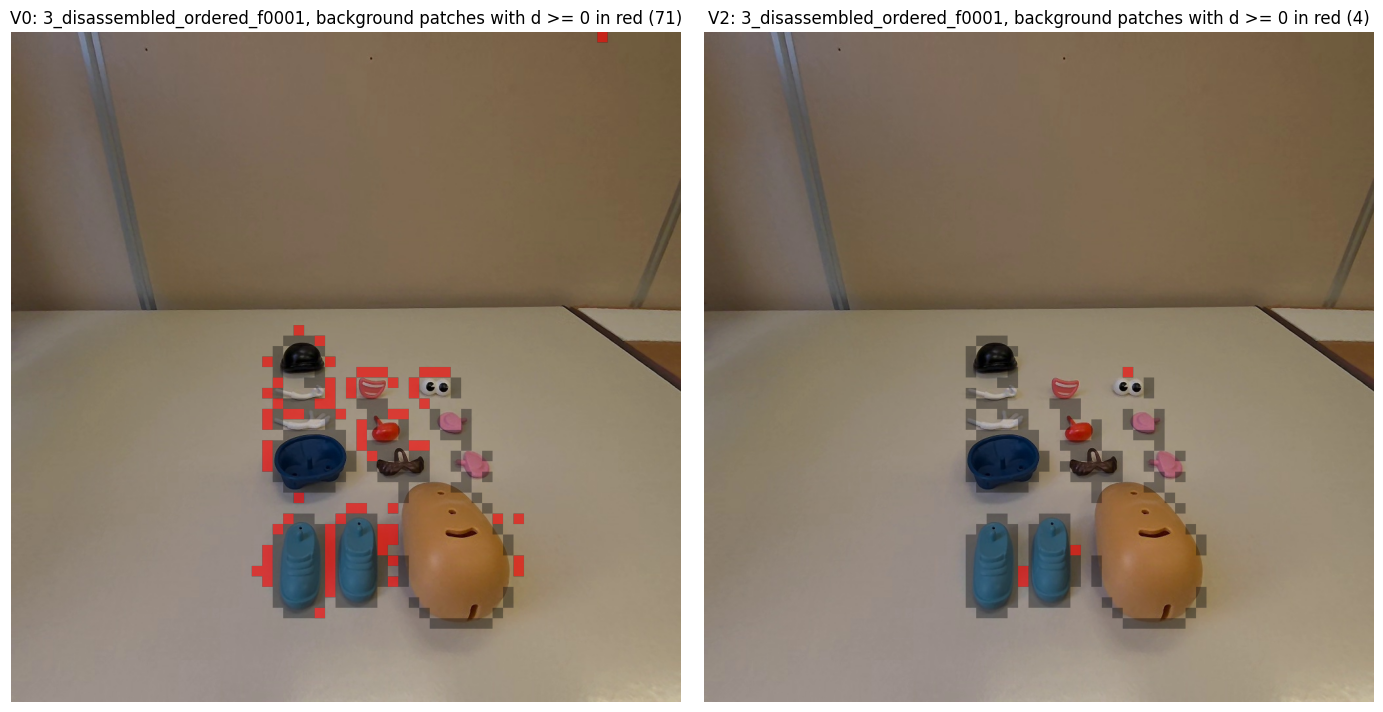

In [16]:
# 4.5 Where are the patches close to the boundary? Counts per reference frame, and the frame with most
# background patches at d >= 0 for V0, shown for both variants
rows = {}
for i, ref in enumerate(REFERENCE_FRAMES):
    background = ref["cv_gt"] == BACKGROUND_ID
    piece = (ref["cv_gt"] != BACKGROUND_ID) & (ref["cv_gt"] != IGNORE_ID)
    row = {}
    for name in VARIANTS:
        d, _ = background_gap(CV_SIMILARITIES[name][i])
        row[f"{name}: background, d >= 0"] = int((background & (d >= 0)).sum())
        row[f"{name}: background, d >= 0.03"] = int((background & (d >= CURRENT_MARGIN)).sum())
        row[f"{name}: piece, d < 0.03"] = int((piece & (d < CURRENT_MARGIN)).sum())
    rows[ref["frame"]] = row
table = pd.DataFrame(rows).T
display(table)

worst = table["V0: background, d >= 0"].idxmax()
i = [ref["frame"] for ref in REFERENCE_FRAMES].index(worst)
ref = REFERENCE_FRAMES[i]
h, w = ref["cv_gt"].shape
image = np.asarray(Image.open(ref["image_path"]).convert("RGB").resize((w * PATCH_SIZE, h * PATCH_SIZE)))
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, name in zip(axes, VARIANTS):
    d, _ = background_gap(CV_SIMILARITIES[name][i])
    false_positive = (ref["cv_gt"] == BACKGROUND_ID) & (d >= 0)
    overlay = np.zeros((h, w, 4))
    overlay[false_positive] = (1.0, 0.0, 0.0, 0.6)                       # red: background patch with d >= 0
    overlay[ref["cv_gt"] == IGNORE_ID] = (0.0, 0.0, 0.0, 0.35)           # dark: ignored patch
    ax.imshow(image)
    ax.imshow(overlay.repeat(PATCH_SIZE, axis=0).repeat(PATCH_SIZE, axis=1))
    ax.set_title(f"{name}: {worst}, background patches with d >= 0 in red ({int(false_positive.sum())})")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [17]:
# 4.5 (continued) Are the V0 false positives on the upper edge of the image extreme-norm patches (pipeline, Appendix A.2)?
norms = np.linalg.norm(ref["features"], axis=-1)
extreme = norms > EXTREME_NORM_FACTOR * np.median(norms)
d, _ = background_gap(CV_SIMILARITIES["V0"][i])
false_positive = (ref["cv_gt"] == BACKGROUND_ID) & (d >= 0)
first_row = np.zeros_like(false_positive)
first_row[0] = True
print(f"{worst}: extreme-norm patches (row, column): {[tuple(map(int, p)) for p in np.argwhere(extreme)]}")
print(f"V0 false positives in the first row: {[tuple(map(int, p)) for p in np.argwhere(false_positive & first_row)]}")
print(f"of which extreme-norm: {int((false_positive & first_row & extreme).sum())}")

3_disassembled_ordered_f0001: extreme-norm patches (row, column): [(0, 55), (0, 56), (0, 57)]
V0 false positives in the first row: [(0, 56)]
of which extreme-norm: 1


Observation 4.5: The background patches with d of at least 0 under V0 are spread over all ten reference frames, from 19 to 71 per frame, so they do not come from one frame or one unannotated object. In 3_disassembled_ordered_f0001, the frame with most of them, they form a ring around the pieces, just outside the ignored boundary patches: they are bleeding of the pieces into the table. Such patches are not counted by the secondary metric, where the boundary ring is ignored. One isolated patch lies on the upper edge of the image, in row 0, column 56. It is one of the three extreme-norm patches of this frame, in row 0, columns 55 to 57 (Section 4.5, continued): a known artifact of the model at the border of the image (pipeline, Appendix A.2). In the pipeline these patches were always assigned to background at margin 0.03 (pipeline, Section 10.2). Here, with V0 at margin 0, this one has d of at least 0 and would be assigned to a piece.

The 18 piece patches of V2 with d below 0.03 lie mostly in the two assembled frames, 7 in 5_assembled_f0002 and 6 in 5_assembled_f0019, where the figure is small and each mounted piece covers few patches. The other 5 are in 3_disassembled_ordered_f0001 (4) and 2_disassembled_caos_f0016 (1).

The margin is chosen on the main metric (Section 1), so for V0 it is chosen mainly to remove the bleeding at the borders of the pieces.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 4: none. The cross-validation by sequence follows Section 1 (Bishop 2006, Sect. 1.3). The extreme-norm check follows the pipeline (Appendix A.2, Section 10.2).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 5 - Choice of the margin by cross-validation

This section chooses the margin m* of each variant on the cross-validated reference frames (Section 4), with the rule of Section 1. The criterion is the mIoU with the arms merged on the main metric, with the counts of all 10 reference frames summed before dividing, as in the previous studies.

A patch takes the best class other than background if its d is at least the margin, and background otherwise. When the patches are sorted by decreasing d and the margin is lowered, they move one at a time from background to their best class, and the confusion matrix changes by one cell at a time. Summing these moves gives the confusion matrix, and so the mIoU, at every value of the margin where at least one label changes. No grid is needed, and all values within the observed range of d are covered, zero and negative values included. This computation is new code. It is checked against assign_labels and frame_miou at margins 0 and 0.03, which must give the same mIoU.

Between two consecutive values of d the labels do not change. The mIoU is therefore constant on intervals of the margin. The chosen margin m* is the middle of the interval where the mIoU is highest. If several separate intervals reach the same highest mIoU, the one closest to zero is taken (Section 1). The mIoU over the 10 pieces is reported at m*, 0 and 0.03, but it does not enter the choice.

How much m* depends on the particular reference frames is measured by a bootstrap: the 10 frames are resampled with replacement, and m* is chosen again on each resample with the same rule. This describes the stability of the choice and is not part of the decision rule.

In [18]:
# 5.1 Cross-validated mIoU as a function of the margin, at every value where a label changes, and the choice of m*
K = len(CLASS_NAMES)
ARM_1, ARM_2 = CLASS_NAMES.index("arm_1"), CLASS_NAMES.index("arm_2")
NO_EXCLUSION = [set() for _ in REFERENCE_FRAMES]          # base is in definition in every reference frame


def frame_moves(name, i):
    """For the valid patches of reference frame i (ground truth not ignored): d, ground truth, best class other than background."""
    valid = REFERENCE_FRAMES[i]["cv_gt"] != IGNORE_ID
    d, best_other = background_gap(CV_SIMILARITIES[name][i])
    return d[valid], REFERENCE_FRAMES[i]["cv_gt"][valid], best_other[valid]


def miou_steps(confusions, merge):
    """mIoU over the pieces for a stack of confusion matrices (S, K, K), as frame_miou (arms merged if merge)."""
    c = confusions
    names, pieces = CLASS_NAMES, PIECE_LABELS
    if merge:                                              # same operation as merge_arms
        c = c.copy()
        c[:, ARM_1, :] += c[:, ARM_2, :]
        c[:, :, ARM_1] += c[:, :, ARM_2]
        keep = [k for k in range(K) if k != ARM_2]
        c = c[:, keep][:, :, keep]
        names, pieces = MERGED_NAMES, MERGED_PIECES
    tp = np.diagonal(c, axis1=1, axis2=2).astype(float)
    fp = c.sum(axis=1) - tp                                # predicted as the class, ground truth another
    fn = c.sum(axis=2) - tp                                # ground truth the class, predicted another
    union = tp + fp + fn
    iou = np.where(union > 0, tp / np.maximum(union, 1), np.nan)
    columns = [j for j, n in enumerate(names) if n in pieces]
    return np.nanmean(iou[:, columns], axis=1)


def margin_curve(moves, merge=True):
    """mIoU at every value of the margin where a label changes. Step k holds for margins in (lower[k], upper[k]]."""
    d = np.concatenate([m[0] for m in moves])
    gt = np.concatenate([m[1] for m in moves])
    best = np.concatenate([m[2] for m in moves])
    order = np.argsort(-d, kind="stable")                  # decreasing d: the order in which patches leave background
    d, gt, best = d[order], gt[order], best[order]
    start = np.zeros((K, K), dtype=np.int32)               # margin above every d: all patches are background
    np.add.at(start, (gt, BACKGROUND_ID), 1)
    moves_matrix = np.zeros((len(d), K, K), dtype=np.int32)
    rows = np.arange(len(d))
    moves_matrix[rows, gt, best] += 1
    moves_matrix[rows, gt, BACKGROUND_ID] -= 1
    confusions = start + np.cumsum(moves_matrix, axis=0)
    last = np.r_[d[1:] != d[:-1], True]                    # one step per distinct value of d
    confusions, upper = confusions[last], d[last]
    lower = np.r_[upper[1:], -np.inf]
    return miou_steps(confusions, merge), lower, upper


def value_at(curve, margin):
    """mIoU of a curve at a given margin."""
    miou, lower, upper = curve
    k = np.flatnonzero((lower < margin) & (margin <= upper))
    return float(miou[k[0]]) if len(k) else np.nan


def choose_margin(curve):
    """Rule of Section 1: middle of the interval with the highest mIoU; among separate intervals with the same
    highest mIoU, the one closest to zero. Returns m*, the interval, the number of best intervals, the best mIoU.
    m* is NaN if the best interval is not bounded by observed values of d."""
    miou, lower, upper = curve
    best = np.nanmax(miou)
    steps = np.flatnonzero(miou == best)
    groups = np.split(steps, np.flatnonzero(np.diff(steps) > 1) + 1)   # contiguous steps form one interval
    intervals = [(lower[g[-1]], upper[g[0]]) for g in groups]           # steps are in decreasing d
    distance = lambda iv: 0.0 if iv[0] < 0 <= iv[1] else min(abs(iv[0]), abs(iv[1]))
    low, high = min(intervals, key=distance)
    m_star = (low + high) / 2 if np.isfinite(low) and np.isfinite(high) else np.nan
    return m_star, (low, high), len(intervals), best


MOVES = {name: [frame_moves(name, i) for i in range(len(REFERENCE_FRAMES))] for name in VARIANTS}
CURVES = {name: {"merged": margin_curve(MOVES[name], merge=True), "10 pieces": margin_curve(MOVES[name], merge=False)}
          for name in VARIANTS}

# Check of the new code against assign_labels + frame_miou, at margins 0 and 0.03, and exact ties
for name in VARIANTS:
    for margin in [NO_MARGIN, CURRENT_MARGIN]:
        confusions = [confusion_matrix(ref["cv_gt"], assign_labels(s, margin))
                      for ref, s in zip(REFERENCE_FRAMES, CV_SIMILARITIES[name])]
        for merge, key in [(True, "merged"), (False, "10 pieces")]:
            direct = frame_miou(confusions, NO_EXCLUSION, merge=merge)
            assert np.isclose(direct, value_at(CURVES[name][key], margin), rtol=0, atol=1e-12), (name, margin, key)
    ties = sum(int((m[0] == 0).sum()) for m in MOVES[name])
    print(f"{name}: curve equals assign_labels + frame_miou at margins 0 and 0.03; exact ties d = 0: {ties}")

CHOSEN = {}
rows = {}
for name in VARIANTS:
    m_star, (low, high), n_best, best = choose_margin(CURVES[name]["merged"])
    CHOSEN[name] = m_star
    rows[name] = {"m*": m_star, "best interval, low": low, "best interval, high": high,
                  "intervals with the best mIoU": n_best, "steps": len(CURVES[name]["merged"][0]),
                  **{f"mIoU arms merged, margin {label}": value_at(CURVES[name]["merged"], m)
                     for label, m in [("m*", m_star), ("0", NO_MARGIN), ("0.03", CURRENT_MARGIN)]},
                  **{f"mIoU 10 pieces, margin {label}": value_at(CURVES[name]["10 pieces"], m)
                     for label, m in [("m*", m_star), ("0", NO_MARGIN), ("0.03", CURRENT_MARGIN)]}}
display(pd.DataFrame(rows).round(4))

V0: curve equals assign_labels + frame_miou at margins 0 and 0.03; exact ties d = 0: 0
V2: curve equals assign_labels + frame_miou at margins 0 and 0.03; exact ties d = 0: 0


,V0,V2
m*,0.1550,0.0206
"best interval, low",0.1536,0.0195
"best interval, high",0.1564,0.0217
intervals with the best mIoU,1.0000,1.0000
steps,38360.0000,38467.0000
"mIoU arms merged, margin m*",0.6865,0.6583
"mIoU arms merged, margin 0",0.4718,0.6497
"mIoU arms merged, margin 0.03",0.5317,0.6563
"mIoU 10 pieces, margin m*",0.6030,0.5895
"mIoU 10 pieces, margin 0",0.4305,0.5846


Observation 5.1: The curve computed from the sorted values of d equals assign_labels and frame_miou at margins 0 and 0.03 for both variants, and there is no exact tie at d = 0. The curve has 38,360 steps for V0 and 38,467 for V2. Each variant has a single interval with the highest cross-validated mIoU with the arms merged. For V0 it lies between 0.1536 and 0.1564, so m* = 0.1550, with a mIoU of 0.687 against 0.472 at margin 0 and 0.532 at 0.03. For V2 it lies between 0.0195 and 0.0217, so m* = 0.0206, with a mIoU of 0.658 against 0.650 at margin 0 and 0.656 at 0.03. Over the 10 pieces, which does not enter the choice, V0 gives 0.603 at m*, 0.431 at 0 and 0.482 at 0.03, and V2 gives 0.590, 0.585 and 0.591: for V2 the value at 0.03 is slightly above the one at m*.

The hypotheses of Section 1 hold in part. m* is positive for V0, and lower for V2 than for V0, but it is not negative for V2. On the reference frames the margin changes V0 much more than V2: between margin 0 and m* the mIoU rises by about 0.21 for V0 and by about 0.009 for V2. For V0, m* lies just above the smallest d of the piece patches, about 0.12 (Observation 4.2), so it removes most of the bleeding at the borders of the pieces at the cost of some piece patches.

These cross-validated values serve to choose the margin, not to compare the variants. The reference frames are partly labelled and each fold has fewer prototypes than the final method. V2 is compared with V0 on the validation frames (Section 6).

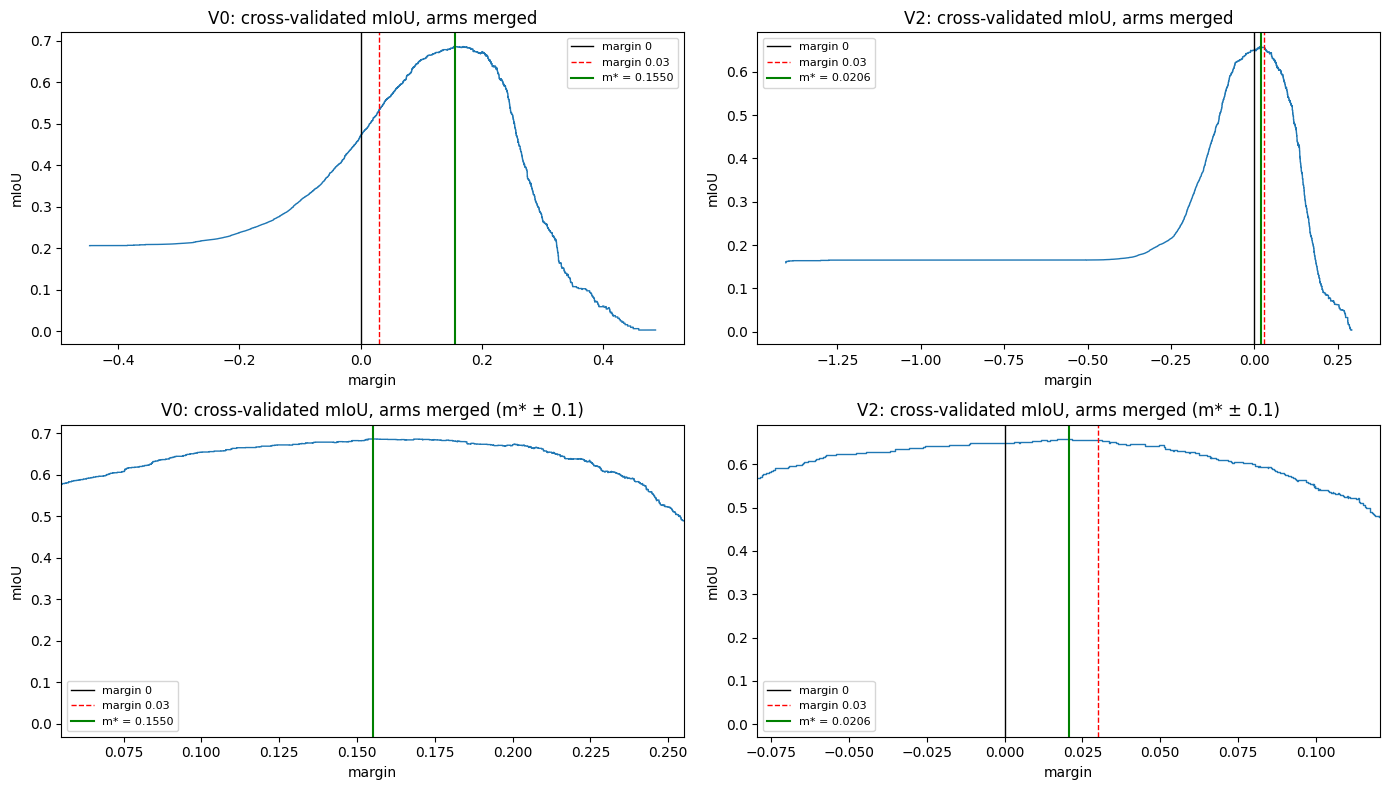

In [19]:
# 5.2 The curves: cross-validated mIoU (arms merged) against the margin, full range and around m*
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for col, name in enumerate(VARIANTS):
    miou, lower, upper = CURVES[name]["merged"]
    for row, zoom in enumerate([None, 0.1]):
        ax = axes[row, col]
        ax.step(upper[::-1], miou[::-1], where="pre", linewidth=1)          # mIoU of step k holds up to upper[k]
        ax.axvline(NO_MARGIN, color="black", linewidth=1, label="margin 0")
        ax.axvline(CURRENT_MARGIN, color="red", linestyle="--", linewidth=1, label="margin 0.03")
        ax.axvline(CHOSEN[name], color="green", linewidth=1.5, label=f"m* = {CHOSEN[name]:.4f}")
        if zoom is not None:                                                 # display only
            ax.set_xlim(CHOSEN[name] - zoom, CHOSEN[name] + zoom)
        ax.set(title=f"{name}: cross-validated mIoU, arms merged" + ("" if zoom is None else f" (m* ± {zoom})"),
               xlabel="margin", ylabel="mIoU")
        ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Observation 5.2: For V0 the cross-validated mIoU rises from about 0.21 at the most negative margins, where every patch takes a class other than background, to 0.472 at margin 0 and 0.532 at 0.03. It reaches its maximum, 0.687, near m* = 0.155, and falls to about 0 at the largest margins, where every patch is background. The maximum is broad: between about 0.10 and 0.21 the curve stays within about 0.03 of its highest value. For V2 the curve is flat, at about 0.16, from about −1.4 to −0.4. It rises steeply from about −0.3 to 0, has its maximum, 0.658, at m* = 0.021, and falls after about 0.05. Around its maximum it is also flat: between about −0.05 and 0.05 it stays between about 0.62 and 0.66, and margins 0, 0.03 and m* give 0.650, 0.656 and 0.658.

For both variants the precise value of the margin matters little within a range of a few hundredths. What matters is the region: around 0.15 for V0 and around 0 for V2. The values read from the figure are approximate; the exact ones are in Section 5.1.

Bootstrap done in about 8 min


,V0,V2
m*,0.1550,0.0206
bootstrap median,0.1691,0.0206
"95% interval, low",0.1531,0.0031
"95% interval, high",0.1874,0.0431
share of resamples with m* < 0,0.0000,0.0060
resamples with no bounded best interval,0.0000,0.0000


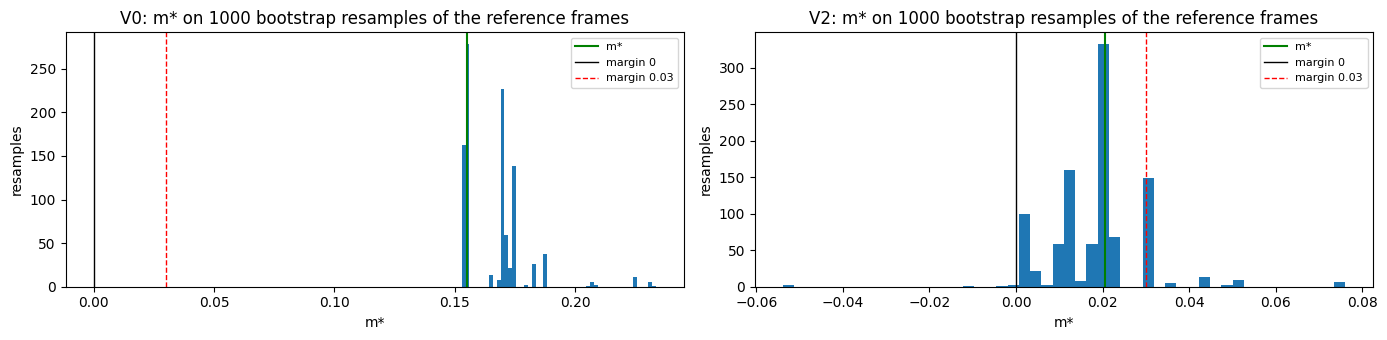

In [20]:
# 5.3 Stability of m*: the 10 reference frames are resampled with replacement and m* is chosen again on each resample
import time

reference_rng = np.random.default_rng(RANDOM_SEED)
REFERENCE_BOOTSTRAP = reference_rng.integers(0, len(REFERENCE_FRAMES), size=(N_BOOTSTRAP, len(REFERENCE_FRAMES)))

BOOTSTRAP_M_STAR = {}
start = time.time()
for name in VARIANTS:
    BOOTSTRAP_M_STAR[name] = np.array([choose_margin(margin_curve([MOVES[name][i] for i in idx]))[0]
                                       for idx in REFERENCE_BOOTSTRAP])
print(f"Bootstrap done in about {(time.time() - start) / 60:.0f} min")

rows = {}
for name in VARIANTS:
    values = BOOTSTRAP_M_STAR[name]
    low, high = percentile_interval(values)
    rows[name] = {"m*": CHOSEN[name], "bootstrap median": float(np.nanmedian(values)),
                  "95% interval, low": low, "95% interval, high": high,
                  "share of resamples with m* < 0": float(np.nanmean(values < 0)),
                  "resamples with no bounded best interval": int(np.isnan(values).sum())}
display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
for ax, name in zip(axes, VARIANTS):
    ax.hist(BOOTSTRAP_M_STAR[name][~np.isnan(BOOTSTRAP_M_STAR[name])], bins=50)    # display only
    ax.axvline(CHOSEN[name], color="green", linewidth=1.5, label="m*")
    ax.axvline(NO_MARGIN, color="black", linewidth=1, label="margin 0")
    ax.axvline(CURRENT_MARGIN, color="red", linestyle="--", linewidth=1, label="margin 0.03")
    ax.set(title=f"{name}: m* on {N_BOOTSTRAP} bootstrap resamples of the reference frames", xlabel="m*", ylabel="resamples")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Observation 5.3: Over 1,000 resamples of the 10 reference frames, m* of V0 has a median of 0.169 and a 95% interval of [0.153, 0.187], and it is never negative. The m* chosen on all frames, 0.155, lies near the lower end of this interval. m* of V2 has a median of 0.021 and an interval of [0.003, 0.043], and it is negative in 0.6% of the resamples. Every resample has a best interval bounded by observed values of d. Neither interval contains 0. The interval of V2 contains 0.03, while the interval of V0 lies far above it. The choice of the margin therefore depends on the particular reference frames by a few hundredths for both variants, and it does not change sign.

In the histograms the values of m* form a few narrow groups rather than a continuous spread, because each resample has its own best interval. For V0 most resamples give m* between 0.153 and 0.19, with a few up to about 0.23. For V2 most resamples give m* between 0 and 0.03, with the largest groups near 0.021, 0.012, 0.030 and 0.002, and a few isolated values near −0.055 and 0.075.

In [21]:
# 5.4 What margin 0.03 removes on the cross-validated reference frames: background patches won by another class
# (d >= 0), far from the objects (outside the boundary ring) or near them (inside it)
rows = {}
for name in VARIANTS:
    far_d, near_d = [], []
    for ref, similarities in zip(REFERENCE_FRAMES, CV_SIMILARITIES[name]):
        d, _ = background_gap(similarities)
        background = ref["cv_gt"] == BACKGROUND_ID
        far = ignore_boundary_ring(ref["cv_gt"], BOUNDARY_RING) == BACKGROUND_ID   # background not next to any object
        near = background & ~far
        far_d.append(d[far & (d >= 0)])
        near_d.append(d[near & (d >= 0)])
    far_d, near_d = np.concatenate(far_d), np.concatenate(near_d)
    for label, values in [("far", far_d), ("near", near_d)]:
        rows[(name, label)] = {"false positives at margin 0": len(values),
                               "removed by 0.03": int((values < CURRENT_MARGIN).sum()),
                               "removed by m*": int((values < CHOSEN[name]).sum()),
                               "median d": float(np.median(values)) if len(values) else np.nan,
                               "largest d": float(values.max()) if len(values) else np.nan}
display(pd.DataFrame(rows).T.round(3))

false positives at margin 0  removed by 0.03  removed by m*  \
V0 far                          40.0             28.0           40.0   
   near                        374.0            142.0          365.0   
V2 far                           3.0              3.0            3.0   
   near                         14.0             11.0           11.0   

         median d  largest d  
V0 far      0.014      0.136  
   near     0.043      0.271  
V2 far      0.002      0.009  
   near     0.013      0.060

Observation 5.4: With V0, 414 background patches are won by another class at margin 0 on the cross-validated reference frames. Only 40 of them are far from the objects, isolated on the table or the wall, with a median d of 0.014. The margin 0.03 removes 28 of these 40. The other 374 are next to an object, with a median d of 0.043, and 0.03 removes 142 of them. With m* = 0.155, V0 loses all 40 far false positives and 365 of the 374 near ones. With V2 there are only 3 far false positives, all with d below 0.009, and 14 near ones, with a median of 0.013. Both 0.03 and m* = 0.021 remove all 3 far ones and 11 of the 14 near ones.

These numbers agree with the visual criterion by which 0.03 was set (Section 1). The false pieces far from the objects have small d, and 0.03 removes most of them while no real piece disappears, since no piece patch of V0 has d below about 0.12 (Observation 4.2). The bleeding at the borders has larger d, and 0.03 leaves most of it. The cross-validation counts this bleeding as error, and its margin removes it as well. Two limits apply: the demo used different prototypes, and 0.03 still leaves 12 of the 40 far false positives, with d up to 0.136.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 5: none new. The rule for m* is that of Section 1. The bootstrap resamples frames with replacement, as in the support-set study (Section 5.4).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 6 - Decision rule on the validation frames

This section applies the decision rule of Section 1. It is the first use of the validation frames in this study, and the margins it checks were fixed in Section 5 without them.

The rule has two steps. First, for each variant, the mIoU at m* is compared with the mIoU at margin 0, with the arms merged on the main metric. If the paired 95% bootstrap interval of the difference lies entirely below zero, the variant uses margin 0, otherwise m*. Second, V2 is compared with V0, each at its decided margin. If the interval lies entirely above zero, the choice of V2 is confirmed. Otherwise the study stops and the result is discussed before any change to the pipeline.

The bootstrap resamples the 8 validation frames with replacement (Koehn 2004, Sect. 6), with the same generator, seed and size as the previous studies. They are therefore the same resamples. This is checked by repeating a comparison already reported: V2 against V0 at margin 0.03 (multi-prototype study, Section 8.1). The mIoU at 0.03 and the mIoU with the boundary ring ignored are reported for every variant and margin, but they do not enter the decision.

In [22]:
# 6.1 Validation confusions of each variant at margin 0, 0.03 and its own m*, and the bootstrap resamples
MARGINS = {name: {"0": NO_MARGIN, "0.03": CURRENT_MARGIN, "m*": CHOSEN[name]} for name in VARIANTS}
CONF = {(name, gt_key, label): variant_confusions(name, margin, gt_key)
        for name in VARIANTS for label, margin in MARGINS[name].items() for gt_key in ["gt_labels", "gt_tolerant"]}

rng = np.random.default_rng(RANDOM_SEED)                 # same generator, seed and size as the previous studies
BOOTSTRAP_INDICES = rng.integers(0, len(VALIDATION_FRAMES), size=(N_BOOTSTRAP, len(VALIDATION_FRAMES)))


def paired(a, b, gt_key="gt_labels", merge=True):
    """Paired comparison of a = (variant, margin label) against b: mIoU difference and its 95% bootstrap interval."""
    ca, cb = CONF[(*a[:1], gt_key, a[1])], CONF[(*b[:1], gt_key, b[1])]
    difference = (bootstrap_miou(ca, EXCLUDED, BOOTSTRAP_INDICES, merge)
                  - bootstrap_miou(cb, EXCLUDED, BOOTSTRAP_INDICES, merge))
    low, high = percentile_interval(difference)
    return {"delta": frame_miou(ca, EXCLUDED, merge=merge) - frame_miou(cb, EXCLUDED, merge=merge),
            "low": low, "high": high}


# Same resamples as the multi-prototype study: V2 against V0 at 0.03 (Section 8.1: 0.135, [0.093, 0.172])
check = {key: round(float(value), 3) for key, value in paired(("V2", "0.03"), ("V0", "0.03")).items()}
print("V2 vs V0 at margin 0.03:", check)
assert check == {"delta": 0.135, "low": 0.093, "high": 0.172}, "The bootstrap resamples differ from the previous studies"
print("Bootstrap resamples identical to the previous studies")

V2 vs V0 at margin 0.03: {'delta': 0.135, 'low': 0.093, 'high': 0.172}
Bootstrap resamples identical to the previous studies


Observation 6.1: V2 against V0 at margin 0.03 gives a difference of 0.135 with a 95% interval of [0.093, 0.172], the values of the multi-prototype study (Section 8.1). The bootstrap resamples are therefore the same as in the previous studies. At margins 0 and 0.03 the mIoU of both variants equals the values of Observation 3.4 (Section 6.4).

In [23]:
# 6.2 Rule, first step: for each variant, m* against margin 0 (arms merged, main metric)
DECIDED = {}
rows = {}
for name in VARIANTS:
    result = paired((name, "m*"), (name, "0"))
    DECIDED[name] = "0" if result["high"] < 0 else "m*"
    rows[name] = {"m*": CHOSEN[name], **result, "interval entirely below 0": bool(result["high"] < 0),
                  "decided margin": MARGINS[name][DECIDED[name]]}
display(pd.DataFrame(rows).T)

,m*,delta,low,high,interval entirely below 0,decided margin
V0,0.154994,0.154281,0.121748,0.190824,False,0.154994
V2,0.020619,-0.003678,-0.007293,-0.000309,True,0.0


Observation 6.2: For V0, m* = 0.155 raises the mIoU with the arms merged from 0.670 at margin 0 to 0.824, a difference of 0.154 with a 95% interval of [0.122, 0.191]. The interval is not below zero, so V0 keeps m*. The concern of Observation 5.1, that m* lies just above the smallest d of the piece patches of the reference frames, is not confirmed on the validation frames.

For V2, m* = 0.021 gives 0.860 against 0.864 at margin 0, a difference of −0.004 with an interval of [−0.007, −0.0003]. The interval lies entirely below zero, so by the rule V2 uses margin 0. It excludes zero only narrowly, and for V2 the margins 0, 0.021 and 0.03 differ by less than 0.005 of mIoU on every metric (Section 6.4).

In [24]:
# 6.3 Rule, second step: V2 against V0, each at its decided margin (arms merged, main metric)
result = paired(("V2", DECIDED["V2"]), ("V0", DECIDED["V0"]))
confirmed = bool(result["low"] > 0)
display(pd.DataFrame({f"V2 (margin {MARGINS['V2'][DECIDED['V2']]:.4f}) vs V0 (margin {MARGINS['V0'][DECIDED['V0']]:.4f})":
                      {**result, "interval entirely above 0": confirmed}}).T)
print("Choice of V2 confirmed" if confirmed else "Choice of V2 NOT confirmed: stop and discuss before changing the pipeline")

,delta,low,high,interval entirely above 0
V2 (margin 0.0000) vs V0 (margin 0.1550),0.039552,0.004936,0.069217,True


Choice of V2 confirmed


Observation 6.3: V2 at margin 0 against V0 at margin 0.155 gives a difference of 0.040 with a 95% interval of [0.005, 0.069]. The interval lies entirely above zero, so the choice of V2 is confirmed. The difference is much smaller than at margin 0.03, where it was 0.135 (Observation 6.1). V0 gains 0.099 from its own margin, from 0.725 at 0.03 to 0.824 at m*, while V2 stays almost the same, from 0.861 at 0.03 to 0.864 at 0. Most of the advantage of V2 measured in the multi-prototype study therefore came from a margin too small for V0.

In [25]:
# 6.4 Reported, outside the rule: mIoU of every variant and margin, both metrics, 10 pieces and arms merged,
# with the paired difference from margin 0 of the same variant
rows = []
for name in VARIANTS:
    for gt_key in ["gt_labels", "gt_tolerant"]:
        for merge in [False, True]:
            for label, margin in MARGINS[name].items():
                row = {"variant": name, "metric": gt_key, "classes": "arms merged" if merge else "10 pieces",
                       "margin": f"{label} ({margin:.4f})",
                       "mIoU": frame_miou(CONF[(name, gt_key, label)], EXCLUDED, merge=merge)}
                if label != "0":
                    result = paired((name, label), (name, "0"), gt_key, merge)
                    row.update({"delta vs 0": result["delta"], "low": result["low"], "high": result["high"]})
                rows.append(row)
display(pd.DataFrame(rows).round(3))

,variant,metric,classes,margin,mIoU,delta vs 0,low,high
0,V0,gt_labels,10 pieces,0 (0.0000),0.626,NaN,NaN,NaN
1,V0,gt_labels,10 pieces,0.03 (0.0300),0.673,0.047,0.035,0.058
2,V0,gt_labels,10 pieces,m* (0.1550),0.753,0.127,0.103,0.155
3,V0,gt_labels,arms merged,0 (0.0000),0.670,NaN,NaN,NaN
4,V0,gt_labels,arms merged,0.03 (0.0300),0.725,0.055,0.042,0.068
5,V0,gt_labels,arms merged,m* (0.1550),0.824,0.154,0.122,0.191
6,V0,gt_tolerant,10 pieces,0 (0.0000),0.742,NaN,NaN,NaN
7,V0,gt_tolerant,10 pieces,0.03 (0.0300),0.753,0.011,0.006,0.016
8,V0,gt_tolerant,10 pieces,m* (0.1550),0.755,0.012,0.003,0.022
9,V0,gt_tolerant,arms merged,0 (0.0000),0.811,NaN,NaN,NaN


Observation 6.4: With the boundary ring ignored, the gain of V0 from m* shrinks to 0.015 with the arms merged, interval [0.005, 0.027], and to 0.012 over the 10 pieces, interval [0.003, 0.022], against 0.154 and 0.127 on the main metric. Almost all the gain of V0 therefore comes from background patches next to the pieces, in agreement with Observation 5.4. On this metric m* and 0.03 give nearly the same mIoU for V0, 0.826 and 0.823.

For V2 every difference from margin 0 lies between −0.005 and −0.004, on both metrics and both sets of classes, and the intervals of m* are below or at zero.

At the decided margins, V0 reaches 0.753 over the 10 pieces and 0.824 with the arms merged on the main metric, and V2 reaches 0.823 and 0.864. With the boundary ring ignored, V0 reaches 0.826 and V2 0.865 with the arms merged. These last differences are descriptive: the rule compares the variants only on the main metric (Section 6.3).

------------------------------------------------------------------------------------------------------------------------------------------

References Section 6:

Koehn 2004, Sect. 6: paired bootstrap resampling; the same resamples are used for both systems, and the interval of the difference is read from the resampled differences.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 7 - Kinds of error and targeted measures

The mIoU summarizes all classes and all errors in one number. This section separates them on the validation frames, with the main ground truth. It compares four configurations: each variant at margin 0.03, as used until now, and at the margin decided in Section 6, 0.155 for V0 and 0 for V2. None of these measures enters the decision rule (Section 1).

The errors are counted patch by patch, in five kinds. A false positive far from the objects is a background patch outside the boundary ring predicted as a piece: a piece that is not there. A false positive near the objects is a background patch inside the ring predicted as a piece: bleeding at the border. A missed piece is a piece patch predicted as background. A piece patch can also be predicted as hand, or as another piece; among the latter, the swaps between arm_1 and arm_2 are counted separately. For the second phase, an isolated group of false positives far from the objects can be read as a piece on the table. The far false positives are therefore also grouped into connected blobs, with 8-connectivity, and the number of blobs and the size of the largest are reported. Base is not counted in the two frames of 1_disassembled_controlled_caos, where it is out of definition, as in every measure of the previous studies.

The per-class IoU uses the arms merged, as the decision rule. The targeted measures are those of the multi-prototype study (Section 6.1), with the same definitions: the body patches predicted as mouth in the frames where the mouth is not mounted, the share of arm patches given the right arm among those predicted as an arm, loose and mounted, and the IoU of the loose mouth in 1_disassembled_controlled_caos. A figure shows the four configurations on the three frames of the known limits.

As stated in Section 1, if the decided margins visibly increase the false positives far from the objects, this is discussed before updating the pipeline.

In [26]:
# 7.1 Kinds of error on the validation frames (main ground truth): each variant at 0.03 and at its decided margin
HAND_ID = CLASS_NAMES.index(HAND_LABEL)
PIECE_IDS = [i for i, name in enumerate(CLASS_NAMES) if name in PIECE_LABELS]
ARMS = [CLASS_NAMES.index("arm_1"), CLASS_NAMES.index("arm_2")]

CONFIGS = {}
for name in VARIANTS:
    for label in ["0.03", DECIDED[name]]:
        CONFIGS[f"{name}, margin {MARGINS[name][label]:.3f}" + (" (decided)" if label == DECIDED[name] else "")] = (name, label)


def predictions(name, label):
    """Labels of the 8 validation frames for one variant at one of its margins."""
    return [assign_labels(s, MARGINS[name][label]) for s in SIMILARITIES[name]]


def error_counts(name, label):
    """Patch counts of each kind of error over the validation frames, and far false positives per frame."""
    counts = dict.fromkeys(["piece patches", "missed (piece -> background)", "piece -> hand", "swapped (piece -> other piece)",
                            "  of which arm_1 <-> arm_2", "background near objects", "false positives near",
                            "background far from objects", "false positives far", "far false-positive blobs",
                            "largest far blob (patches)"], 0)
    per_frame = {}
    for i, (val, pred) in enumerate(zip(VALIDATION_FRAMES, predictions(name, label))):
        pieces = [c for c in PIECE_IDS if c not in EXCLUDED[i]]          # base out of definition in the caos frames
        gt, tolerant = val["gt_labels"], val["gt_tolerant"]
        gt_piece, pred_piece = np.isin(gt, pieces), np.isin(pred, pieces)
        far_background = tolerant == BACKGROUND_ID
        near_background = (gt == BACKGROUND_ID) & ~far_background
        swapped = gt_piece & pred_piece & (pred != gt)
        far_fp = far_background & pred_piece
        blobs, n_blobs = ndimage.label(far_fp, structure=np.ones((3, 3)))
        counts["piece patches"] += int(gt_piece.sum())
        counts["missed (piece -> background)"] += int((gt_piece & (pred == BACKGROUND_ID)).sum())
        counts["piece -> hand"] += int((gt_piece & (pred == HAND_ID)).sum())
        counts["swapped (piece -> other piece)"] += int(swapped.sum())
        counts["  of which arm_1 <-> arm_2"] += int((swapped & np.isin(gt, ARMS) & np.isin(pred, ARMS)).sum())
        counts["background near objects"] += int(near_background.sum())
        counts["false positives near"] += int((near_background & pred_piece).sum())
        counts["background far from objects"] += int(far_background.sum())
        counts["false positives far"] += int(far_fp.sum())
        counts["far false-positive blobs"] += n_blobs
        if n_blobs:
            counts["largest far blob (patches)"] = max(counts["largest far blob (patches)"],
                                                       int(np.bincount(blobs.ravel())[1:].max()))
        per_frame[val["frame"]] = int(far_fp.sum())
    return counts, per_frame


ERRORS = {config: error_counts(*key) for config, key in CONFIGS.items()}
display(pd.DataFrame({config: counts for config, (counts, _) in ERRORS.items()}))
print("False positives far from the objects, per validation frame:")
display(pd.DataFrame({config: per_frame for config, (_, per_frame) in ERRORS.items()}))

,"V0, margin 0.030","V0, margin 0.155 (decided)","V2, margin 0.030","V2, margin 0.000 (decided)"
piece patches,1066,1066,1066,1066
missed (piece -> background),0,9,14,6
piece -> hand,0,0,0,0
swapped (piece -> other piece),95,94,55,57
of which arm_1 <-> arm_2,26,26,12,13
background near objects,1536,1536,1536,1536
false positives near,175,3,0,3
background far from objects,28458,28458,28458,28458
false positives far,5,0,0,0
far false-positive blobs,2,0,0,0


False positives far from the objects, per validation frame:


,"V0, margin 0.030","V0, margin 0.155 (decided)","V2, margin 0.030","V2, margin 0.000 (decided)"
assembly_2_f0003,0,0,0,0
assembly_2_f0017,0,0,0,0
assembly_2_f0030,0,0,0,0
assembly_2_f0046,0,0,0,0
assembly_2_f0057,0,0,0,0
assembly_2_f0068,0,0,0,0
1_disassembled_controlled_caos_f0001,1,0,0,0
1_disassembled_controlled_caos_f0016,4,0,0,0


Observation 7.1: The validation frames contain 1066 piece patches, 1536 background patches near the objects and 28,458 far from them. At the decided margins neither variant has false positives far from the objects. At margin 0.03, V0 had 5, in 2 blobs, the largest of 4 patches, and V2 had none. They were all in the two frames of 1_disassembled_controlled_caos: 1 in f0001 and 4 in f0016. The control of Section 1 on the far false positives is therefore met.

For V0 the decided margin, 0.155, reduces the false positives near the objects from 175 to 3, and misses 9 piece patches against none at 0.03. The swaps between pieces are almost unchanged, 94 against 95, of which 26 between arm_1 and arm_2 in both cases. For V2 the decided margin, 0, misses 6 piece patches against 14 at 0.03, and adds 3 false positives near the objects against none. Its swaps are 57 against 55, of which 13 and 12 between the arms. No piece patch is predicted as hand in any configuration.

At the decided margins the two variants differ less in the background than in the pieces. V0 and V2 have the same number of false positives near the objects, 3, and miss 9 and 6 piece patches. V2 swaps fewer pieces, 57 against 94, and fewer arms, 13 against 26.

In [27]:
# 7.2 Per-class IoU, arms merged, main metric: each variant at 0.03 and at its decided margin
display(pd.DataFrame({config: frame_iou(CONF[(name, "gt_labels", label)], EXCLUDED, merge=True)
                      for config, (name, label) in CONFIGS.items()}, index=MERGED_NAMES).round(3))

,"V0, margin 0.030","V0, margin 0.155 (decided)","V2, margin 0.030","V2, margin 0.000 (decided)"
background,0.991,0.990,0.999,0.999
body,0.768,0.881,0.942,0.940
base,0.785,0.901,0.945,0.945
hat,0.919,0.978,0.993,1.000
eyes,0.636,0.662,0.831,0.831
ear,0.719,0.920,0.919,0.919
nose,0.729,0.796,0.737,0.737
moustache,0.803,0.803,0.828,0.814
mouth,0.519,0.519,0.651,0.651
arm,0.651,0.961,0.899,0.939


Observation 7.2: With its decided margin, V0 improves on almost every piece compared with 0.03: body from 0.768 to 0.881, base from 0.785 to 0.901, hat from 0.919 to 0.978, eyes from 0.636 to 0.662, ear from 0.719 to 0.920, nose from 0.729 to 0.796, arm from 0.651 to 0.961. Mouth and moustache are unchanged, at 0.519 and 0.803. Hand falls from 0.910 to 0.668: the margin decides between background and every other class, so it also rejects hand patches (Section 1). Hand is not in the mIoU, so this loss does not appear in the decision rule.

For V2 the decided margin changes little: hat from 0.993 to 1.000, arm from 0.899 to 0.939, moustache from 0.828 to 0.814, body from 0.942 to 0.940. Hand goes from 0.965 to 0.969.

At the decided margins V2 is better than V0 on body, base, hat, eyes, moustache and mouth. V0 is better on arm, 0.961 against 0.939, and on nose, 0.796 against 0.737, and the two are equal on ear, 0.920 and 0.919. With the arms merged, a swap between the two arms counts as correct.

In [28]:
# 7.3 Targeted measures of the multi-prototype study (Section 6.1), same definitions, main metric
INDEX = {val["frame"]: i for i, val in enumerate(VALIDATION_FRAMES)}
NO_MOUTH_FRAMES = ["assembly_2_f0003", "assembly_2_f0017",
                   "1_disassembled_controlled_caos_f0001", "1_disassembled_controlled_caos_f0016"]
MOUNTED_ARM_FRAMES = ["assembly_2_f0068"]
LOOSE_ARM_FRAMES = [f for f in INDEX if f not in MOUNTED_ARM_FRAMES]
LOOSE_MOUTH_FRAMES = ["1_disassembled_controlled_caos_f0001", "1_disassembled_controlled_caos_f0016"]
BODY, MOUTH = CLASS_NAMES.index("body"), CLASS_NAMES.index("mouth")


def right_arm_share(confusions, frames):
    """Among arm patches predicted as an arm, the share predicted as the right arm."""
    right = sum(confusions[INDEX[f]][a, a] for f in frames for a in ARMS)
    any_arm = sum(confusions[INDEX[f]][np.ix_(ARMS, ARMS)].sum() for f in frames)
    return right / any_arm if any_arm else np.nan


rows = {}
for config, (name, label) in CONFIGS.items():
    c = CONF[(name, "gt_labels", label)]
    rows[config] = {
        "body patches predicted as mouth (mouth not mounted)": int(sum(c[INDEX[f]][BODY, MOUTH] for f in NO_MOUTH_FRAMES)),
        "right arm share, loose": right_arm_share(c, LOOSE_ARM_FRAMES),
        "right arm share, mounted (f0068)": right_arm_share(c, MOUNTED_ARM_FRAMES),
        "mouth IoU, both caos frames": frame_iou(c, EXCLUDED, frames=[INDEX[f] for f in LOOSE_MOUTH_FRAMES])[MOUTH],
        "mouth IoU, side view (caos f0016)": frame_iou(c, EXCLUDED, frames=[INDEX["1_disassembled_controlled_caos_f0016"]])[MOUTH],
    }
display(pd.DataFrame(rows).T.round(3))

,body patches predicted as mouth (mouth not mounted),"right arm share, loose","right arm share, mounted (f0068)","mouth IoU, both caos frames","mouth IoU, side view (caos f0016)"
"V0, margin 0.030",5.0,0.724,0.833,0.583,0.333
"V0, margin 0.155 (decided)",5.0,0.721,0.833,0.583,0.333
"V2, margin 0.030",0.0,0.844,1.000,0.727,0.667
"V2, margin 0.000 (decided)",0.0,0.840,1.000,0.727,0.667


Observation 7.3: At margin 0.03 the targeted measures equal those of the multi-prototype study (Section 6.1). The decided margins barely change them. In the frames where the mouth is not mounted, V0 predicts 5 body patches as mouth at both margins, and V2 none. Among the loose arm patches predicted as an arm, the right arm gets 0.721 with V0 at 0.155 and 0.840 with V2 at 0; on the mounted arms of f0068, 0.833 and 1.000. The IoU of the loose mouth in the two frames of 1_disassembled_controlled_caos is 0.583 with V0 and 0.727 with V2, and in the side view 0.333 and 0.667. The advantages of V2 on the empty slot, the identity of the arms and the loose mouth therefore do not depend on the margin.

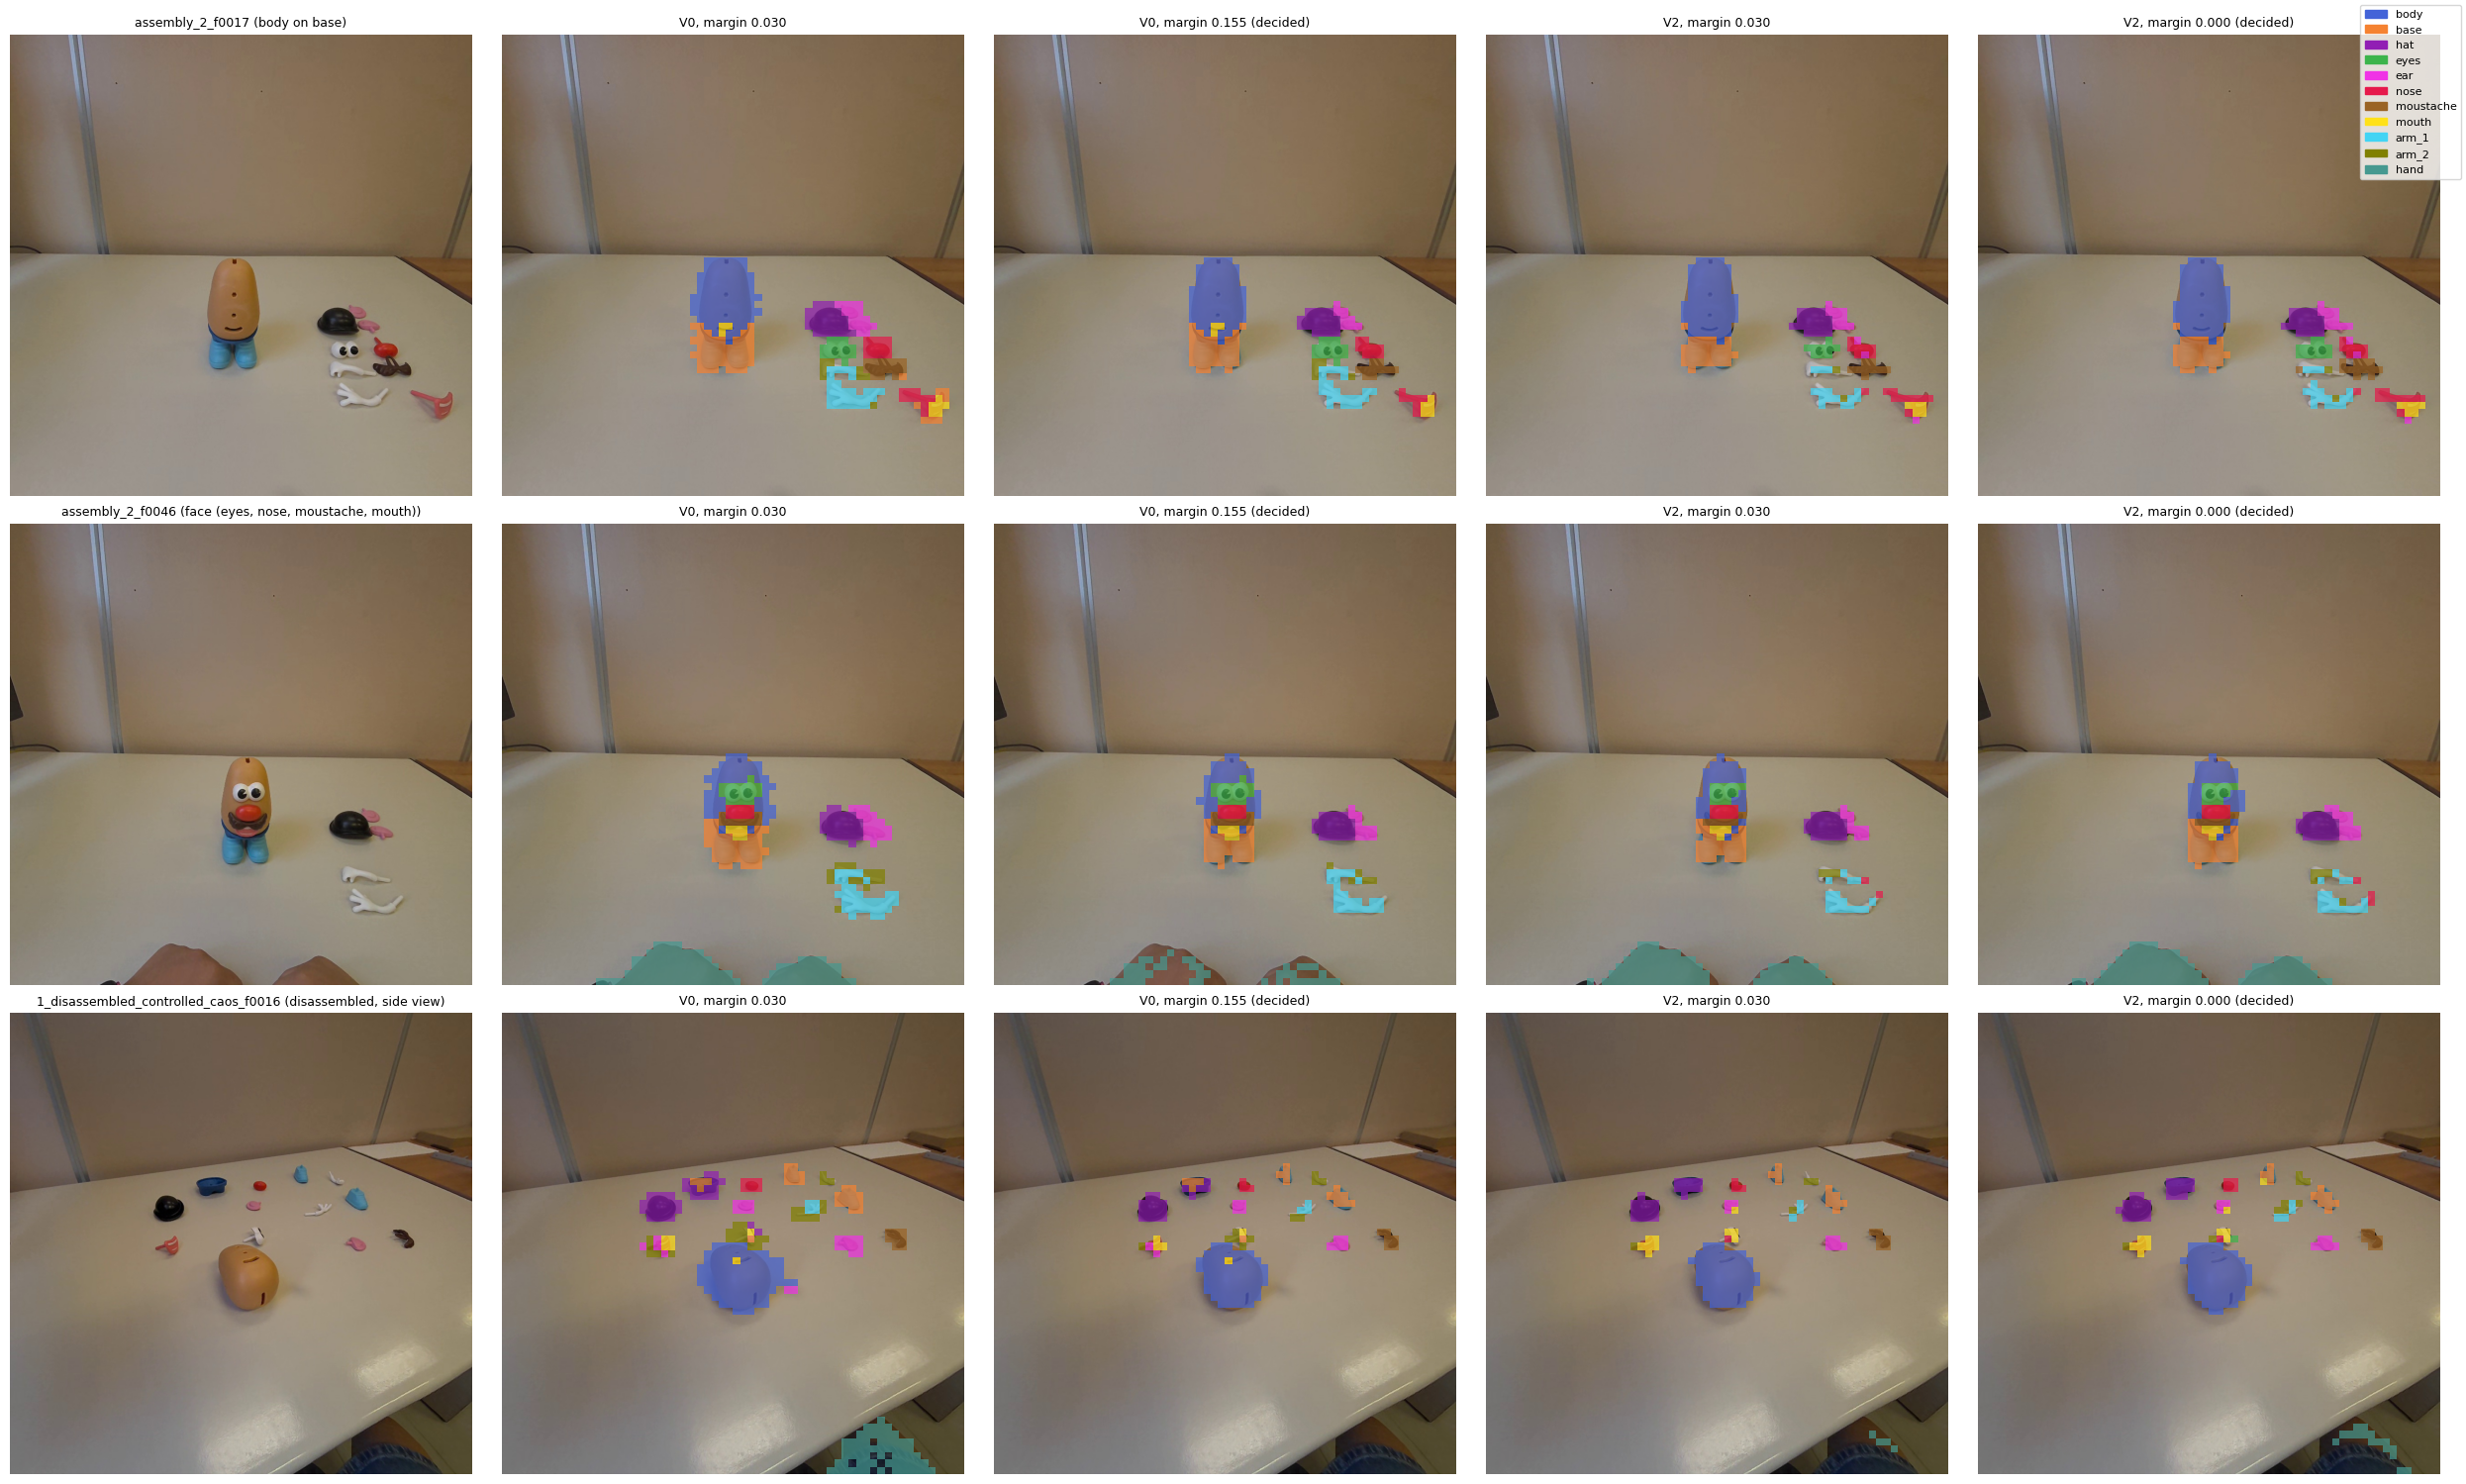

In [29]:
# 7.4 The four configurations on the three frames of the known limits (multi-prototype study, Section 6.2)
FIGURE_FRAMES = ["assembly_2_f0017", "assembly_2_f0046", "1_disassembled_controlled_caos_f0016"]

fig, axes = plt.subplots(len(FIGURE_FRAMES), len(CONFIGS) + 1, figsize=(5 * (len(CONFIGS) + 1), 5 * len(FIGURE_FRAMES)))
for row, frame in zip(axes, FIGURE_FRAMES):
    i = INDEX[frame]
    image = Image.open(frame_path(frame)).convert("RGB")
    row[0].imshow(image)
    row[0].set_title(f"{frame} ({VALIDATION_FRAMES[i]['stage']})", fontsize=9)
    for ax, (config, (name, label)) in zip(row[1:], CONFIGS.items()):
        pred = assign_labels(SIMILARITIES[name][i], MARGINS[name][label])
        alpha = np.where(pred == BACKGROUND_ID, 0.0, 0.7)[..., None]
        ax.imshow(image)
        ax.imshow(np.concatenate([label_grid_to_rgb(pred), alpha], axis=-1),
                  extent=(0, image.width, image.height, 0), interpolation="nearest")
        ax.set_title(config, fontsize=9)
    for ax in row:
        ax.axis("off")
fig.legend(handles=[mpatches.Patch(color=CLASS_COLORS[n], label=n) for n in CLASS_NAMES[1:]], loc="upper right", fontsize=8)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "predictions_at_decided_margins.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 7.4: In all three frames V0 at 0.03 predicts regions larger than the pieces, which spread onto the table; at 0.155 they follow the pieces closely, much like V2. In assembly_2_f0017 both margins of V0 still predict a few mouth patches on the empty slot of the body, while V2 predicts body there. The loose mouth, bottom right, is predicted mostly as nose with a few mouth patches in every configuration. In assembly_2_f0046 V0 at 0.155 predicts the hands at the bottom only in part, the rest as background, while V2 at both margins predicts them almost entirely. The loose arms are partly predicted as arm_2 by V0 and mostly as arm_1 by V2, which also adds a few nose patches at their ends. In 1_disassembled_controlled_caos_f0016, V2 at 0.03 and at 0 give almost the same prediction.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 7: none. The targeted measures and the figure follow the multi-prototype study (Sections 6.1 and 6.2); near and far follow the boundary ring of the secondary metric (support-set study).

------------------------------------------------------------------------------------------------------------------------------------------

## Section 8 - Continuous perception on assembly_2 (exploratory)

This section is exploratory and outside the decision rule: the margins were decided in Section 6, and nothing is chosen here. It asks whether, at the decided margins, V2 keeps its advantages in the continuous perception of assembly_2 and recovers what it lost at margin 0.03: the loose arm_2 and the hat on the table, and the stability at rest (Section 1).

The video is read once, with C-RADIO on the GPU. For every frame and variant, d and the best class other than background are saved. From these two values the labels at any margin follow exactly as in assign_labels, without running the model again. Before the analysis, V2 at margin 0.03 is checked against the labels saved for the Addendum of the multi-prototype study, which were computed with the same prototypes. V0 is not expected to match: the V0 of the Addendum used the prototypes of the pipeline, built from 8 reference frames, while the V0 of this study uses the 10 frames. The saved labels of the pipeline V0 are therefore kept as an extra column, so that the numbers of the Addendum stay visible.

The measures are those of the Addendum, computed by src/utils/continuous_analysis.py unchanged, against the event log annotated on the raw video (configs/assembly_2_events.json). Their thresholds are provisional, as stated in the script, and they are used here only to compare with the Addendum.

A diagnostic then recomputes the main measures of V2 for margins from −0.10 to 0.10, in steps of 0.01. The steps only set the resolution of the curves. The question is whether some margin recovers arm_2 on the table, and at what cost to the empty mouth slot and to the stability, that is, whether the loss of arm_2 is a matter of the margin at all. Finally a video of V2 at its decided margin is written for viewing.

In [30]:
# 8.1 Event log, analysis script (unchanged) and the prototypes of both variants
from utils.continuous_analysis import analyse, load_events

EVENTS = load_events(EVENTS_PATH)                         # absolute path: the default in the script is relative
print(f"{len(EVENTS)} events in the log")

prototypes_v0, owners_v0 = VARIANTS["V0"]                 # 12 prototypes: classification on the CPU, about 20 ms
V2_GPU = tuple(torch.as_tensor(x, device=DEVICE) for x in sort_by_class(*VARIANTS["V2"]))  # moved once to the GPU
print(f"V2 on the GPU: {len(V2_GPU[1])} prototypes")


def labels_at(name, margin):
    """Labels of every video frame at a given margin, from the saved d and best class: the same rule as assign_labels.
    For margin >= 0 a patch with d = 0 exactly goes to background, as argmax gives the tie to background."""
    d, best = CONT[name]["d"], CONT[name]["best"]
    keep = (d >= margin) & (d > 0) if margin >= 0 else d >= margin
    return np.where(keep, best, BACKGROUND_ID).astype(np.uint8)

11 events in the log
V2 on the GPU: 39125 prototypes


In [31]:
# 8.2 One pass over assembly_2: for every frame and variant, d and the best class other than background
cap = cv2.VideoCapture(str(VIDEO_PATH))
FPS = cap.get(cv2.CAP_PROP_FPS)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
CONT = {name: {"d": [], "best": []} for name in VARIANTS}
start, index = time.time(), 0
while True:
    ok, frame_bgr = cap.read()
    if not ok:
        break
    features, _ = extractor.extract(Image.fromarray(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)))
    for name, similarities in [("V0", class_similarities(features, prototypes_v0, owners_v0)),
                               ("V2", class_similarities_gpu(features, *V2_GPU))]:
        d, best = background_gap(similarities)
        CONT[name]["d"].append(d.astype(np.float32))
        CONT[name]["best"].append(best.astype(np.uint8))
    index += 1
    if index % 250 == 0:
        print(f"{index}/{n_frames} frames, {(time.time() - start) / 60:.1f} min")
cap.release()
CONT = {name: {key: np.stack(values) for key, values in arrays.items()} for name, arrays in CONT.items()}
np.savez_compressed(OUTPUT_DIR / "assembly_2_gaps.npz", fps=FPS, class_names=np.array(CLASS_NAMES),
                    **{f"{name}_{key}": values for name, arrays in CONT.items() for key, values in arrays.items()})
print(f"Done: {index} frames in about {(time.time() - start) / 60:.0f} min, saved to {OUTPUT_DIR / 'assembly_2_gaps.npz'}")

250/2444 frames, 2.2 min
500/2444 frames, 4.4 min
750/2444 frames, 6.7 min
1000/2444 frames, 9.0 min
1250/2444 frames, 11.3 min
1500/2444 frames, 13.6 min
1750/2444 frames, 15.8 min
2000/2444 frames, 18.1 min
2250/2444 frames, 20.3 min
Done: 2444 frames in about 22 min, saved to c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_margin_study\assembly_2_gaps.npz


Observation 8.2: The 2444 frames of assembly_2 were processed in about 20 to 25 minutes, about half a second per frame, mostly for C-RADIO. The values of d and the best class other than background of both variants are saved in outputs/phase_1_margin_study/assembly_2_gaps.npz.

In [32]:
# 8.3 Regression check against the labels saved for the Addendum (multi-prototype study)
saved = {"V2": np.load(SCRATCH_DIR / "assembly_2_continuous_labels_V2.npz")["labels"],
         "V0 (pipeline, 8 reference frames)": np.load(SCRATCH_DIR / "assembly_2_continuous_labels.npz")["labels"]}
rows = {}
for saved_name, variant in [("V2", "V2"), ("V0 (pipeline, 8 reference frames)", "V0")]:
    new = labels_at(variant, CURRENT_MARGIN)
    assert new.shape == saved[saved_name].shape, f"Different number of frames for {saved_name}"
    different = new != saved[saved_name]
    rows[f"{variant} of this study vs saved {saved_name}, margin 0.03"] = {
        "patches compared": different.size, "patches with a different label": int(different.sum()),
        "frames with any difference": int(different.any(axis=(1, 2)).sum())}
display(pd.DataFrame(rows).T)

,patches compared,patches with a different label,frames with any difference
"V2 of this study vs saved V2, margin 0.03",10010624,0,0
"V0 of this study vs saved V0 (pipeline, 8 reference frames), margin 0.03",10010624,9004,2329


Observation 8.3: V2 at margin 0.03 gives exactly the labels saved for the Addendum: no patch differs out of 10,010,624. V0 of this study differs from the V0 of the pipeline used in the Addendum in 9004 patches, 0.09% of the total, spread over 2329 frames. The difference comes from the prototypes, built from 10 reference frames here and from 8 in the pipeline.

In [33]:
# 8.4 The measures of the Addendum (continuous_analysis.py, unchanged) for every configuration
CONT_CONFIGS = {"V0 pipeline (8 frames), margin 0.030 [Addendum]": SCRATCH_DIR / "assembly_2_continuous_labels.npz"}
for config, (name, label) in CONFIGS.items():
    path = OUTPUT_DIR / f"assembly_2_labels_{name}_{label.replace('*', 'star')}.npz"   # '*' is not allowed in Windows file names
    np.savez_compressed(path, labels=labels_at(name, MARGINS[name][label]), fps=FPS, class_names=np.array(CLASS_NAMES))
    CONT_CONFIGS[config] = path

RESULTS = {config: analyse(path, EVENTS) for config, path in CONT_CONFIGS.items()}

for measure in ["seen on table before pick", "seen on body after mount",
                "on body before pick (false positive)", "patches on body, final pause"]:
    print(f"\n{measure}:")
    display(pd.DataFrame({config: r["per piece"][measure] for config, r in RESULTS.items()}).round(2))

print("\nmouth on the empty slot (frames 345-540):")
display(pd.DataFrame({config: r["mouth slot"] for config, r in RESULTS.items()}).round(2))
print("mounted arms, patches by side (frames 2010-2360; arm_1 is on the image right, arm_2 on the image left):")
display(pd.DataFrame({config: {f"{arm}, {side}": r["arms mounted"][arm][side]
                               for arm in ["arm_1", "arm_2"] for side in ["image left", "image right"]}
                      for config, r in RESULTS.items()}))
for column in ["rest (changes/s)", "moving (changes/s)"]:
    print(f"\nflicker, {column}:")
    display(pd.DataFrame({config: r["flicker"][column] for config, r in RESULTS.items()}).round(2))
print("\nend of the video (frames 2400-2444), mean off-body patches per frame:")
display(pd.DataFrame({config: r["end (off-body patches)"] for config, r in RESULTS.items()}).round(1))


seen on table before pick:


,"V0 pipeline (8 frames), margin 0.030 [Addendum]","V0, margin 0.030","V0, margin 0.155 (decided)","V2, margin 0.030","V2, margin 0.000 (decided)"
hat,0.77,0.90,0.89,0.55,0.54
eyes,0.99,0.99,0.99,0.99,0.99
ear,1.00,1.00,1.00,0.99,1.00
nose,0.96,0.95,0.93,0.92,0.92
moustache,0.99,0.99,0.99,0.99,0.99
mouth,0.43,0.64,0.64,0.72,0.72
arm_1,0.97,0.97,0.97,0.96,0.96
arm_2,0.99,0.99,0.51,0.10,0.12



seen on body after mount:


,"V0 pipeline (8 frames), margin 0.030 [Addendum]","V0, margin 0.030","V0, margin 0.155 (decided)","V2, margin 0.030","V2, margin 0.000 (decided)"
hat,1.00,1.00,1.00,1.00,1.00
eyes,0.99,0.99,0.99,0.99,0.99
ear,1.00,1.00,1.00,1.00,1.00
nose,0.97,0.97,0.97,0.96,0.96
moustache,0.91,0.91,0.91,0.90,0.90
mouth,0.89,0.92,0.90,0.75,0.75
arm_1,0.41,0.45,0.42,0.97,0.98
arm_2,1.00,1.00,0.99,0.96,0.97



on body before pick (false positive):


,"V0 pipeline (8 frames), margin 0.030 [Addendum]","V0, margin 0.030","V0, margin 0.155 (decided)","V2, margin 0.030","V2, margin 0.000 (decided)"
hat,0.05,0.01,0.01,0.08,0.14
eyes,0.00,0.00,0.00,0.00,0.00
ear,0.04,0.02,0.01,0.01,0.02
nose,0.01,0.00,0.00,0.00,0.00
moustache,0.00,0.00,0.00,0.00,0.00
mouth,1.00,0.92,0.92,0.00,0.00
arm_1,0.00,0.00,0.00,0.00,0.00
arm_2,0.12,0.11,0.05,0.00,0.00


... (8 outputs left out)


flicker, moving (changes/s):


,"V0 pipeline (8 frames), margin 0.030 [Addendum]","V0, margin 0.030","V0, margin 0.155 (decided)","V2, margin 0.030","V2, margin 0.000 (decided)"
base,0.00,0.00,0.05,0.00,0.00
hat,0.65,0.49,0.71,0.68,0.79
eyes,0.54,0.54,0.54,0.54,0.54
ear,0.33,0.33,0.35,0.27,0.35
nose,0.74,0.79,0.71,0.87,0.87
moustache,0.84,0.90,0.79,1.01,0.90
mouth,1.01,1.44,1.55,4.00,3.95
arm_1,1.23,1.23,0.98,1.06,1.88
arm_2,1.33,1.39,2.48,1.63,2.64



end of the video (frames 2400-2444), mean off-body patches per frame:


,"V0 pipeline (8 frames), margin 0.030 [Addendum]","V0, margin 0.030","V0, margin 0.155 (decided)","V2, margin 0.030","V2, margin 0.000 (decided)"
base,34.5,47.2,14.8,14.8,15.6
hat,11.2,10.7,6.7,4.7,5.1
eyes,0.0,0.0,0.0,0.0,0.0
ear,4.9,4.7,1.1,0.1,0.3
nose,0.2,0.2,0.0,0.0,0.0
moustache,0.1,0.0,0.0,0.0,0.0
mouth,0.5,0.3,0.3,0.3,0.3
arm_1,3.0,2.9,2.9,2.0,2.2
arm_2,18.0,17.4,8.0,3.0,3.5


Observation 8.4: The column of the pipeline V0 gives the numbers of the Addendum, for example arm_2 seen on the table before its pick in 0.99 of the frames, the hat in 0.77 and the loose mouth in 0.43, and the mouth on the empty slot in every frame.

For V2, the decided margin 0 gives almost the same results as 0.03. The loose arm_2 is seen on the table in 0.12 of the frames against 0.10, the hat in 0.54 against 0.55, the loose mouth in 0.72 in both. At rest, the presence of arm_2 changes 5.17 times per second against 5.19, and that of the mouth 2.24 against 2.28. The advantages of V2 are also kept: no mouth on the empty slot, the mounted arms on their correct sides (arm_1 on the image right in 1814 patches and never on the left, arm_2 on the image left in 1717 patches and on the right in 21), and fewer off-body patches at the end of the video, where the monitor and the controller are in view (base 15.6 per frame against 34.5 for the pipeline V0, arm_2 3.5 against 18.0). The hat is predicted on the body before its pick in 0.14 of the frames against 0.08 at 0.03.

For V0, the decided margin 0.155 removes part of the loose arm_2 seen at 0.03: on the table in 0.51 of the frames against 0.99, with 2.15 changes per second at rest against 0.20. The margin that removes the bleeding at the borders on the validation frames (Observation 6.4) also removes small loose pieces seen from far in the video. This does not change the decision, since the chosen variant is V2, but the validation frames do not show this effect.

,arm_2 seen on table before pick,hat seen on table before pick,mouth seen on table before pick,mouth on empty slot (share of frames),arm_2 flicker at rest (changes/s),mouth flicker at rest (changes/s)
-0.10,0.41,0.41,0.72,0.0,0.63,2.19
-0.09,0.40,0.41,0.72,0.0,0.89,2.19
-0.08,0.38,0.42,0.72,0.0,1.16,2.19
-0.07,0.37,0.43,0.72,0.0,1.30,2.19
-0.06,0.34,0.45,0.72,0.0,1.43,2.19
-0.05,0.32,0.45,0.72,0.0,1.86,2.19
-0.04,0.30,0.48,0.72,0.0,2.17,2.19
-0.03,0.26,0.51,0.72,0.0,2.75,2.19
-0.02,0.20,0.52,0.72,0.0,3.51,2.24
-0.01,0.15,0.54,0.72,0.0,4.21,2.24


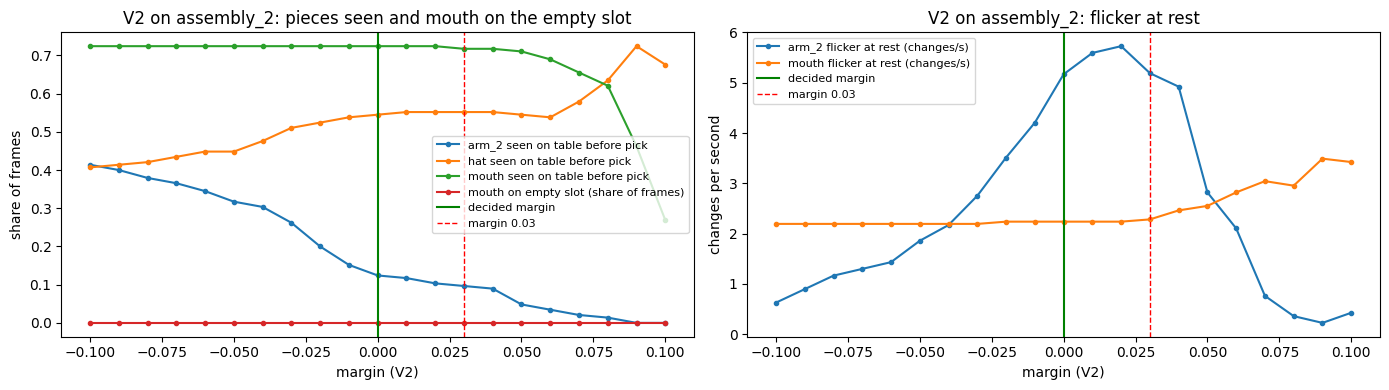

In [34]:
# 8.5 Diagnostic (exploratory): main measures of V2 as the margin varies, negative values included.
# The steps of 0.01 only set the resolution of the curves; nothing is chosen here.
SWEEP = np.round(np.arange(-0.10, 0.1001, 0.01), 2)
sweep_path = OUTPUT_DIR / "sweep_tmp.npz"
rows = {}
for margin in SWEEP:
    np.savez_compressed(sweep_path, labels=labels_at("V2", margin), fps=FPS, class_names=np.array(CLASS_NAMES))
    r = analyse(sweep_path, EVENTS)
    rows[margin] = {f"{piece} seen on table before pick": r["per piece"].loc[piece, "seen on table before pick"]
                    for piece in ["arm_2", "hat", "mouth"]}
    rows[margin].update({"mouth on empty slot (share of frames)": r["mouth slot"]["frames with >= 1 mouth patch on body"],
                         "arm_2 flicker at rest (changes/s)": r["flicker"].loc["arm_2", "rest (changes/s)"],
                         "mouth flicker at rest (changes/s)": r["flicker"].loc["mouth", "rest (changes/s)"]})
sweep_path.unlink()
SWEEP_TABLE = pd.DataFrame(rows).T
display(SWEEP_TABLE.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for column in SWEEP_TABLE.columns[:4]:
    axes[0].plot(SWEEP_TABLE.index, SWEEP_TABLE[column], marker="o", markersize=3, label=column)
for column in SWEEP_TABLE.columns[4:]:
    axes[1].plot(SWEEP_TABLE.index, SWEEP_TABLE[column], marker="o", markersize=3, label=column)
for ax, ylabel in zip(axes, ["share of frames", "changes per second"]):
    ax.axvline(MARGINS["V2"][DECIDED["V2"]], color="green", linewidth=1.5, label="decided margin")
    ax.axvline(CURRENT_MARGIN, color="red", linestyle="--", linewidth=1, label="margin 0.03")
    ax.set(xlabel="margin (V2)", ylabel=ylabel)
    ax.legend(fontsize=8)
axes[0].set_title("V2 on assembly_2: pieces seen and mouth on the empty slot")
axes[1].set_title("V2 on assembly_2: flicker at rest")
plt.tight_layout()
plt.show()

Observation 8.5: As the margin of V2 goes from 0.10 down to −0.10, the loose arm_2 is seen on the table more often, but at most in 0.41 of the frames, at −0.10. At the same time the hat is seen less often, from 0.54 at margin 0 to 0.41 at −0.10. The loose mouth stays at 0.72 for every margin up to 0.04 and falls above it, to 0.27 at 0.10. The mouth never appears on the empty slot, at any margin. The flicker of arm_2 at rest peaks at about 5.7 changes per second near 0.02 and falls to 0.63 at −0.10, as arm_2 is seen more often. The flicker of the mouth stays at about 2.2 below 0.03 and rises above it.

Hypothesis, from these curves: the loss of the loose arm_2 by V2 is not a matter of the margin. No margin in this range recovers it to the level of V0, and lower margins worsen the hat. This agrees with Sections 4 and 5, where very few piece patches of V2 had d close to 0.

In quiet frames, with no hand near the arms, V2 sees the loose arm_2 much more often (Observation 8.7).

In [35]:
# 8.6 Video of V2 at its decided margin, for viewing only
cap = cv2.VideoCapture(str(VIDEO_PATH))
size = (int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
video_path = OUTPUT_DIR / "assembly_2_V2_decided_margin.mp4"
writer = cv2.VideoWriter(str(video_path), cv2.VideoWriter_fourcc(*"mp4v"), FPS, size)
v2_labels = labels_at("V2", MARGINS["V2"][DECIDED["V2"]])
MIN_BLOB = 5               # smallest blob that gets a name, as in the pipeline (Section 11): display only
for index in range(len(v2_labels)):
    ok, frame_bgr = cap.read()
    if not ok:
        break
    shown = render_overlay(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB), v2_labels[index], MIN_BLOB)
    cv2.putText(shown, f"V2, margin {MARGINS['V2'][DECIDED['V2']]:.3f}  frame {index}  ({index / FPS:.1f} s)", (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
    writer.write(cv2.cvtColor(shown, cv2.COLOR_RGB2BGR))
cap.release()
writer.release()
print(f"Video written: {video_path}")

Video written: c:\Users\ADV\Universita\Magistrale\Tesi\vad-project\outputs\phase_1_margin_study\assembly_2_V2_decided_margin.mp4


Observation 8.6 (visual, from watching the whole video): When the figure is complete, every piece is recognized. Objects that enter the scene and were never annotated are still partly predicted as pieces. False positives also appear on the hands and on the base: pieces are predicted on parts of the hands and the sleeves, and on the base once it is placed. The hat becomes unstable once it is picked up and held in the hand. The mouth is recognized as mouth only when seen from the front; its peg, seen from other angles, is predicted as nose. These are visual impressions on one video, not measures; Section 8.8 shows some of these moments.

In [36]:
# 8.7 Loose arms on the table (exploratory): frames where both arms are loose and no hand is on them, from the end of
# the last ear event (hands_off 1652) to 5 frames before the pick of arm_1 (1770), as BEFORE_PICK of the script
both_loose = slice(1652, 1770 - 5)
rows = {}
for config, r in RESULTS.items():
    arm_1, arm_2 = r["off"]["arm_1"][both_loose], r["off"]["arm_2"][both_loose]
    rows[config] = {"frames": arm_1.size,
                    "arm_1 present (>= 3 patches)": float((arm_1 >= 3).mean()), "arm_2 present (>= 3 patches)": float((arm_2 >= 3).mean()),
                    "mean arm_1 patches": float(arm_1.mean()), "mean arm_2 patches": float(arm_2.mean())}
display(pd.DataFrame(rows).T.round(2))

,frames,arm_1 present (>= 3 patches),arm_2 present (>= 3 patches),mean arm_1 patches,mean arm_2 patches
"V0 pipeline (8 frames), margin 0.030 [Addendum]",113.0,0.96,0.97,26.64,14.52
"V0, margin 0.030",113.0,0.96,0.97,26.55,14.43
"V0, margin 0.155 (decided)",113.0,0.96,0.89,20.51,4.58
"V2, margin 0.030",113.0,0.95,0.77,13.51,3.77
"V2, margin 0.000 (decided)",113.0,0.95,0.83,15.22,5.54


Observation 8.7: In the 113 frames where both arms lie on the table and no hand is near them (1652 to 1765), V2 at its decided margin sees arm_1 in 0.95 of the frames and arm_2 in 0.83, with 15.2 and 5.5 patches on average. At 0.03 it sees arm_2 in 0.77 of the frames. V0 at 0.03 sees both arms in 0.96 and 0.97 of the frames, with 26.6 and 14.4 patches. At its decided margin, 0.155, it sees arm_2 in 0.89 of the frames with 4.6 patches.

Every configuration finds fewer arm_2 patches than arm_1 patches, V0 included, so the counts alone cannot tell a swap between the arms from a difference in how the two arms are seen. The frames of Section 8.8 show both effects for V2 at different moments: before the hand touches the arms at 1440, the loose arm_2 is swapped with arm_1, and next to its pick, with the hands at work, it is predicted mostly as background.

In these quiet frames V2 sees arm_2 much more often than the measure "seen on table before pick" suggests, 0.83 against 0.12 (Observation 8.4). That measure covers the 150 frames before the pick of arm_2, 1738 to 1883, which include the pick of arm_1 at 1770, its mounting at 1802, and the hands at work until 1875. Hypothesis: V2 loses the loose arm_2 mainly while the hands work next to it, not when the scene is still. The measures of continuous_analysis.py depend strongly on their windows, which the script itself marks as provisional; they must be justified before a formal study of continuous perception.

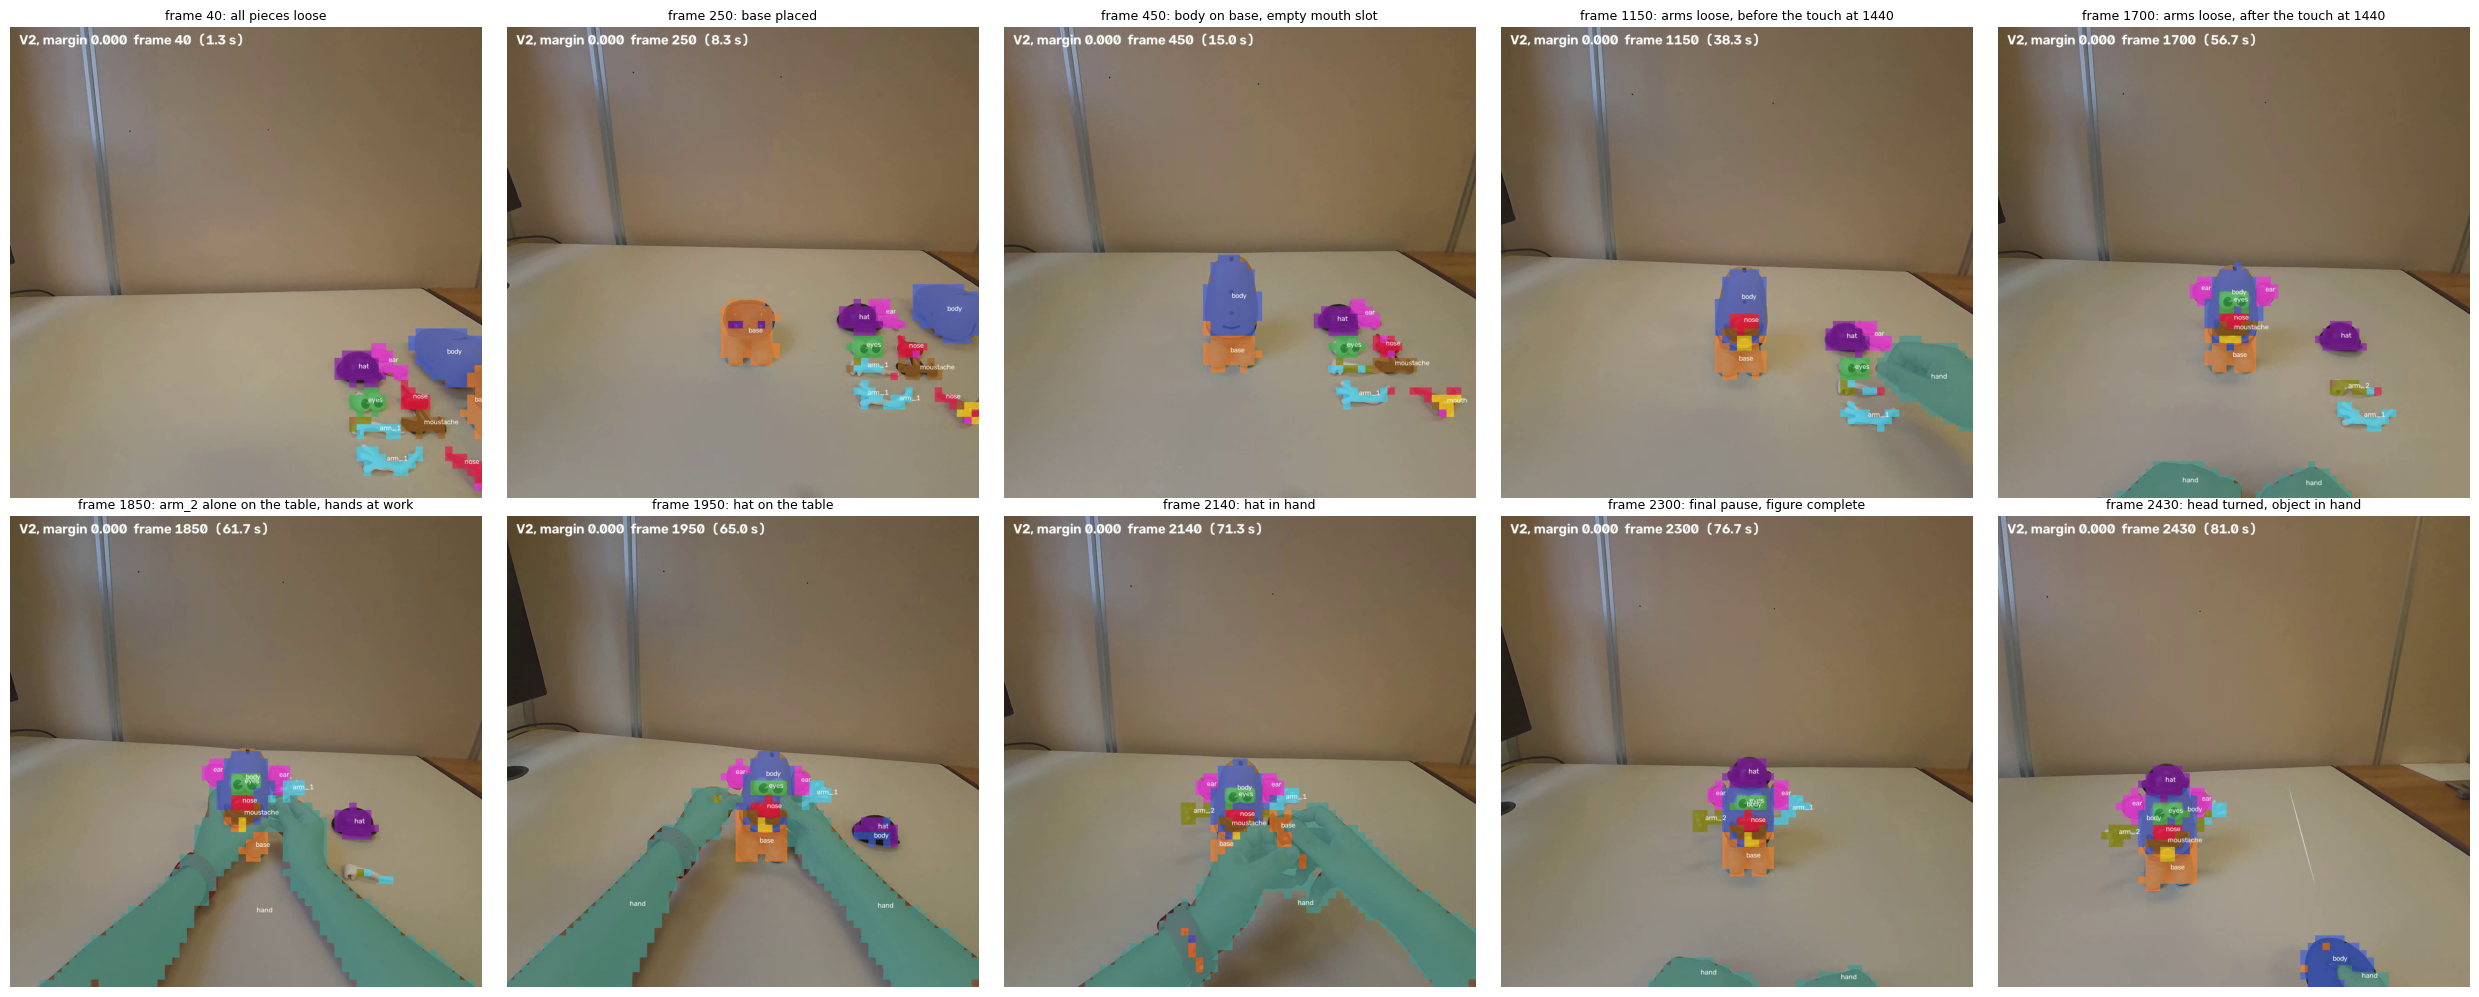

In [37]:
# 8.8 Frames of the V2 video (decided margin) at moments of the event log, for a visual check
SHOWN_FRAMES = {40: "all pieces loose", 250: "base placed", 450: "body on base, empty mouth slot",
                1150: "arms loose, before the touch at 1440", 1700: "arms loose, after the touch at 1440",
                1850: "arm_2 alone on the table, hands at work", 1950: "hat on the table", 2140: "hat in hand",
                2300: "final pause, figure complete", 2430: "head turned, object in hand"}
cap = cv2.VideoCapture(str(video_path))
shown = {}
for index in range(max(SHOWN_FRAMES) + 1):
    ok, frame_bgr = cap.read()
    if not ok:
        break
    if index in SHOWN_FRAMES:
        shown[index] = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
cap.release()

fig, axes = plt.subplots(2, 5, figsize=(25, 10))
for ax, (index, what) in zip(axes.ravel(), SHOWN_FRAMES.items()):
    ax.imshow(shown[index])
    ax.set_title(f"frame {index}: {what}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "assembly_2_V2_key_frames.png", dpi=100, bbox_inches="tight")
plt.show()

Observation 8.8: In frames 1700 and 1850 the identity of the loose arms can be read: at 1700 the upper arm is predicted as arm_2 and the lower as arm_1, and at 1850, after arm_1 has been picked, the upper arm is the one left on the table, which the event log identifies as arm_2 (pick at 1888). With this reference, in frames 40, 250 and 1150, before the hand touches the arms at 1440, V2 predicts both loose arms as arm_1, with only one or two arm_2 patches at the left end of the upper arm: the loose arm_2 is swapped with arm_1. At 1850, with the hands at work next to it, arm_2 is predicted mostly as background, with one arm_2 and two arm_1 patches.

The loose mouth is predicted mostly as nose, with a few mouth patches, in frames 40 and 250. A few false positives fall on other pieces and on the hands: hat patches on the base just placed (250), body patches on the hat on the table (1950), base patches on the sleeve while the hat is held (2140). The hat in the hand is predicted only in part. The object held at the end of the video is predicted as body (2430). In the final pause (2300) every piece of the complete figure is recognized, with the arms on their correct sides.

------------------------------------------------------------------------------------------------------------------------------------------

References Section 8: none. The measures are those of the Addendum of the multi-prototype study (src/utils/continuous_analysis.py, unchanged), against the event log configs/assembly_2_events.json.

------------------------------------------------------------------------------------------------------------------------------------------

## Section 9 - Decision and conclusions

Decision. The pipeline should use V2 with margin 0: each patch takes its most similar class, with no background rejection. The margin of V0 chosen by cross-validation is 0.155. At their decided margins, V2 is better than V0 by 0.040 of mIoU with the arms merged, with a paired 95% interval of [0.005, 0.069] (Section 6.3), so the choice of V2 made in the multi-prototype study is confirmed.

Why V2 needs no margin. On the reference frames the cross-validation chooses 0.021 for V2 (Section 5.1). On the validation frames this value is slightly worse than 0, by 0.004 with an interval of [−0.007, −0.0003], and the rule then sets the margin to 0 (Section 6.2). For V2, margins between 0 and 0.03 change the mIoU by less than 0.005 on every metric (Section 6.4). The practical result is that V2 needs no margin on these data.

Why V0 needs a large margin. With V0 the background patches next to the pieces have d from 0 up to about 0.27, while the pieces start at about 0.12 (Sections 4.2 and 5.4). The margin 0.155 removes almost all this bleeding: the false positives next to the objects fall from 175 at 0.03 to 3 (Section 7.1), and the mIoU with the arms merged rises from 0.725 to 0.824 (Section 6.4). With the boundary ring ignored the gain is only 0.015, so it comes almost entirely from the borders.

The margin 0.03. The value was set by watching the first video demo, to remove false pieces on empty background (Section 1). On the reference frames it removes 28 of the 40 false positives of V0 far from the objects, but only 142 of the 374 next to them (Section 5.4). This agrees with the visual criterion, which sees isolated false pieces but not the bleeding at the borders. At 0.03, V0 was penalized by that bleeding, and most of the advantage of V2 measured in the multi-prototype study, 0.135, came from it.

The hypotheses of Section 1. m* is positive for V0, as expected, and lower for V2, but not negative. The hypothesis that the background prototypes of V2 win by small differences, and that a lower margin would recover the lost pieces, is not confirmed. Very few piece patches of V2 have d close to 0 on the reference frames (Section 4.3), and in the video no margin between −0.10 and 0.10 recovers the loose arm_2 to the level of V0, while lower margins worsen the hat (Section 8.5).

The question of the study. With its own margin, V2 keeps its advantages: no mouth on the empty slot, the right identity of the arms, a better loose mouth, on the validation frames (Section 7.3) and in the video (Section 8.4). It does not recover coverage and stability in the video, and this is not a matter of the margin. The loose arm_2 is swapped with arm_1 in part of the video, before the hand touches the arms at frame 1440, and is lost to background while the hands work next to it (Sections 8.7 and 8.8). In the video V2 also predicts pieces on objects never annotated, on the hands and on the base, and the hat held in the hand is unstable (Sections 8.6 and 8.8).

Comparison with the first version, and a test outside this study. The first version of the perception notebook recognized the loose mouth and arms better in the video of assembly_2. Two differences explain most of it. Its support set included the two frames of 1_disassembled_controlled_caos, which are validation frames in the current protocol and show the loose pieces on the same table as the videos. Its video classified only still scenes and held the labels while the scene moved, so it could not show flicker or errors during the hand work. The labelling rule does not explain the difference (pipeline, Appendix A.3; support-set study, Section 6.8). An exploratory test outside this notebook (notebooks/scratch_support_swap.ipynb) added the two frames to the support set of V2, at margin 0. The loose arm_2 was then seen on the table before its pick in 0.44 of the frames instead of 0.12, its flicker at rest fell from 5.17 to 1.48 changes per second, and the hat on the table rose from 0.54 to 0.67. On the 6 annotated frames of assembly_2 the IoU of the mouth rose from 0.625 to 0.781, and the classification of V2 took about 95 ms per frame instead of 82. The swap of the loose arms early in the video and the false positives on objects never annotated did not change. The support set, not the margin, is therefore the lever for the loose pieces. The test uses validation data and is optimistic, and a support set with these frames requires a new validation set.

The margin and the hand. The margin decides between background and every other class, the hand included. At 0.155 it lowers the IoU of the hand of V0 from 0.910 to 0.668 (Section 7.2). The hand is not in the mIoU, so the rule does not see this effect. It does not concern V2 at margin 0.

A bias, not a rejection. The margin assigns uncertain patches to a class, background, rather than withholding a decision. It is therefore a bias between two classes, which moves the decision boundary when the two errors have different costs (Mensink et al. 2013, Sect. 3.4; Bishop 2006, Sect. 1.5.2). It is not a reject option in the sense of Chow (1970, Sect. I and II) and Bishop (2006, Sect. 1.5.3), where the classifier declines to assign any class.

Generality. The margin is chosen from the reference frames alone, which the method needs anyway, so in a new assembly the same procedure can be repeated without annotating other frames (Cawley and Talbot 2010, Sect. 6). The values found here, 0.155 for V0 and 0 for V2, belong to these data: they depend on the scale of the similarities of each classifier (Section 4.2) and on the setting. With a different support set the procedure must be run again.

Limits. The validation set has 8 frames, and several choices of the previous studies were made on the same frames, so its results are optimistic; the test sequence, assembly_1, has not been read. The reference frames are partly labelled, and each fold of the cross-validation has fewer prototypes than the final method. For V2 the veto excludes zero only narrowly. The analysis of the video is exploratory: one video, no annotations, and measures with provisional windows and thresholds, on which the results depend strongly (Section 8.7). Effects visible only in the video, such as the loss of the loose arm_2 by V0 at 0.155 (Section 8.4), do not appear on the validation frames.

Next steps. First, rebuild the validation set by annotating more frames of assembly_2, so that it stays independent of a support set that includes 1_disassembled_controlled_caos. Then study the support set for the loose pieces, with the states to cover declared beforehand, including the mouth when its front is visible. The cross-validation by sequence of this study can show which reference frames are redundant without using the validation frames, so that the support set can also become smaller. The margin is then chosen again with the procedure of this study, and the pipeline is updated to the decided configuration, with a regression check. The other open problems are the hat held in the hand, and objects never seen, which are the open set problem of Scheirer et al. (2013, Sect. 2), to study on the robustness set. The test on assembly_1 comes at the end of the first phase.

In [38]:
# 9.1 Decided configuration, saved for the pipeline update
decision = {
    "variant": "V2",
    "background_margin": float(MARGINS["V2"][DECIDED["V2"]]),
    "decided_margin": {name: float(MARGINS[name][DECIDED[name]]) for name in VARIANTS},
    "m_star_cross_validation": {name: float(CHOSEN[name]) for name in VARIANTS},
    "m_star_bootstrap_95": {name: [float(x) for x in percentile_interval(BOOTSTRAP_M_STAR[name])] for name in VARIANTS},
    "v2_vs_v0_at_decided_margins": {k: float(v) for k, v in paired(("V2", DECIDED["V2"]), ("V0", DECIDED["V0"])).items()},
    "reference_frames": [ref["frame"] for ref in REFERENCE_FRAMES],
    "selection": "leave-one-sequence-out cross-validation on the reference frames; middle of the interval with the highest "
                 "mIoU (arms merged, main metric); veto on the validation frames against margin 0 (Section 1)",
    "note": "valid for this support set of 10 frames; with another support set the margin must be chosen again",
}
with open(OUTPUT_DIR / "decision.json", "w") as f:
    json.dump(decision, f, indent=2)
print(json.dumps(decision, indent=2))

{
  "variant": "V2",
  "background_margin": 0.0,
  "decided_margin": {
    "V0": 0.15499374270439148,
    "V2": 0.0
  },
  "m_star_cross_validation": {
    "V0": 0.15499374270439148,
    "V2": 0.020618915557861328
  },
  "m_star_bootstrap_95": {
    "V0": [
      0.1531127691268921,
      0.18741735741496043
    ],
    "V2": [
      0.0030605196952819824,
      0.04309642314910889
    ]
  },
  "v2_vs_v0_at_decided_margins": {
    "delta": 0.039552446273245945,
    "low": 0.004936338346185665,
    "high": 0.06921688250393684
  },
  "reference_frames": [
    "5_assembled_f0002",
    "caos_f0149",
    "5_assembled_f0019",
    "3_disassembled_ordered_f0001",
    "2_disassembled_caos_f0016",
    "Take_3_1_Base_f0099",
    "Take_3_1_Base_f0131",
    "caos_f0211",
    "4_partially_assembled_f0002",
    "caos_f0043"
  ],
  "selection": "leave-one-sequence-out cross-validation on the reference frames; middle of the interval with the highest mIoU (arms merged, main metric); veto on the validatio

------------------------------------------------------------------------------------------------------------------------------------------

References Section 9:

Mensink et al. 2013, Sect. 3.4: class-specific bias of the nearest class mean classifier.

Bishop 2006, Sect. 1.5.2: the decision that minimizes the expected loss moves the boundary when errors have different costs. Sect. 1.5.3: the reject option, where inputs whose largest posterior probability is below a threshold receive no class.

Chow 1970, Sect. I and II: a reject is a withheld decision; the optimum rule rejects a pattern when its largest posterior probability is below a threshold.

Cawley and Talbot 2010, Sect. 6: model selection repeated independently, also in operational use.

Scheirer et al. 2013, Sect. 2: open space risk, the risk of labelling inputs far from any known training data.

------------------------------------------------------------------------------------------------------------------------------------------